In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

import metpy.calc as mpcalc
from metpy.cbook import get_test_data

from metpy.units import units
import numpy as np
import csv
import os
from netCDF4 import Dataset

from wrf import (getvar, interplevel, vertcross,
                 CoordPair, ALL_TIMES, to_np,ll_to_xy,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times)

/glade/work/fdemartin/conda-envs/jupyter/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


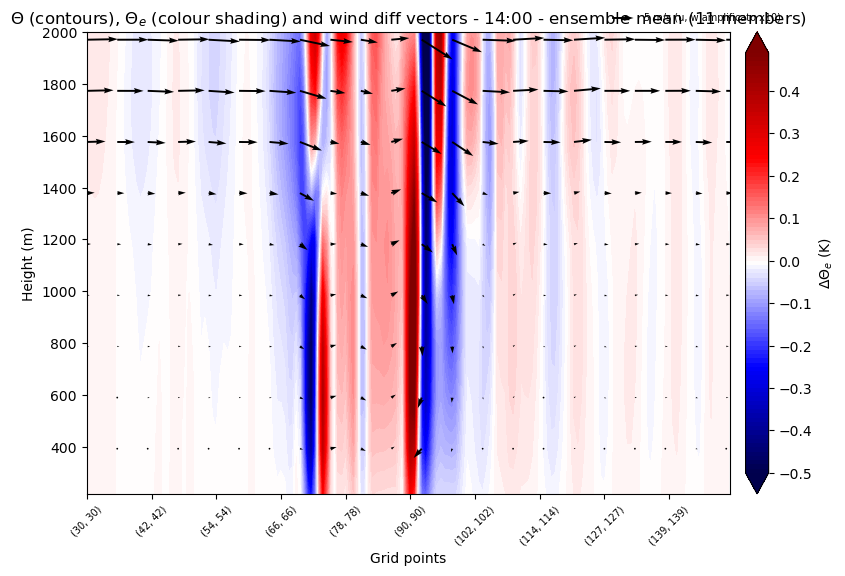

In [32]:
exp0 = 'no_urban'
base_path = "/glade/derecho/scratch/fdemartin/ens/no_urban/"
base_path2 = "/glade/derecho/scratch/fdemartin/ens/30km/"
var = 'theta'
start_time = datetime(2023, 5, 31, 14, 0, 0)
members = range(0, 11)  # ensemble members da 0 a 10 (inclusi)
start_point = CoordPair(x=30, y=30)
end_point   = CoordPair(x=150, y=150)
levels_w = np.arange(-0.5, 0.5, 0.01)
levels_thetae = np.arange(320, 350, 1)
levels_diff = np.arange(-0.5, 0.5, 0.01)
levels_diff2 = np.arange(-2, 2, 0.1)
quiver_scale = 150          # scala delle frecce (aumenta se sono troppo lunghe, diminuisci se troppo corte)
quiver_xskip = 8           # sottocampionamento lungo la sezione (ogni N punti)
quiver_zskip = 1           # sottocampionamento in verticale (ogni N livelli)
w_vector_amplify = 10      # fattore di amplificazione della componente verticale (w << u tipicamente)

# solo il primo time step
time_str = start_time.strftime("%Y-%m-%d_%H:%M:%S")

# angolo della sezione (in coordinate griglia x,y) per proiettare il vento
# lungo la direzione start_point -> end_point (vento tangente alla sezione)
section_angle = np.arctan2(end_point.y - start_point.y, end_point.x - start_point.x)

theta_cross_list = []
w_cross_list = []
wind_u_cross_list = []  # componente orizzontale (lungo la sezione) del vettore vento
wind_w_cross_list = []  # componente verticale del vettore vento

for member in members:
    file_name = f"{base_path}{member}/wrfout_d01_{time_str}"
    file_name2 = f"{base_path2}{member}/wrfout_d01_{time_str}"

    if not os.path.exists(file_name) or not os.path.exists(file_name2):
        print(f"Errore: file non trovato per member {member}")
        continue

    ncfile = Dataset(file_name)
    theta = getvar(ncfile, var, timeidx=0)
    w = getvar(ncfile, 'theta_e', timeidx=0)  # DataArray xarray, con metadata intatta
    z = getvar(ncfile, "z", timeidx=0)        # DataArray xarray
    ua = getvar(ncfile, "ua", timeidx=0)      # vento zonale earth-relative (m/s)
    va = getvar(ncfile, "va", timeidx=0)      # vento meridionale earth-relative (m/s)
    wa = getvar(ncfile, "wa", timeidx=0)      # vento verticale (m/s)

    ncfile2 = Dataset(file_name2)
    theta2 = getvar(ncfile2, var, timeidx=0)
    w2 = getvar(ncfile2, 'theta_e', timeidx=0)
    z2 = getvar(ncfile2, "z", timeidx=0)
    ua2 = getvar(ncfile2, "ua", timeidx=0)
    va2 = getvar(ncfile2, "va", timeidx=0)
    wa2 = getvar(ncfile2, "wa", timeidx=0)

    theta_diff = theta2 - theta
    w_diff = w2 - w

    # vento tangente alla sezione (proiezione di u,v lungo la direzione della sezione)
    wind_tan = ua * np.cos(section_angle) + va * np.sin(section_angle)
    wind_tan2 = ua2 * np.cos(section_angle) + va2 * np.sin(section_angle)
    wind_tan_diff = wind_tan2# - wind_tan
    wa_diff = wa2 - wa

    theta_cross = vertcross(theta_diff, z, wrfin=ncfile,
                             start_point=start_point, end_point=end_point,
                             latlon=True, meta=True)
    w_cross = vertcross(w_diff, z, wrfin=ncfile,
                         start_point=start_point, end_point=end_point,
                         latlon=True, meta=True)
    wind_u_cross = vertcross(wind_tan_diff, z, wrfin=ncfile,
                              start_point=start_point, end_point=end_point,
                              latlon=True, meta=True)
    wind_w_cross = vertcross(wa_diff, z, wrfin=ncfile,
                              start_point=start_point, end_point=end_point,
                              latlon=True, meta=True)

    ncfile.close()
    ncfile2.close()

    theta_cross_list.append(theta_cross)
    w_cross_list.append(w_cross)
    wind_u_cross_list.append(wind_u_cross)
    wind_w_cross_list.append(wind_w_cross)

if len(theta_cross_list) == 0:
    raise RuntimeError("Nessun ensemble member trovato per questo time step.")

# media sugli ensemble members
theta_cross_mean = np.mean([to_np(tc) for tc in theta_cross_list], axis=0)
w_cross_mean = np.mean([to_np(wc) for wc in w_cross_list], axis=0)
wind_u_cross_mean = np.mean([to_np(wc) for wc in wind_u_cross_list], axis=0)
wind_w_cross_mean = np.mean([to_np(wc) for wc in wind_w_cross_list], axis=0)

# uso il primo cross section come riferimento per le coordinate (uguali per tutti i member)
ref_cross = theta_cross_list[0]
x_ticks = np.arange(ref_cross.shape[-1])
vert_vals = to_np(ref_cross.coords["vertical"])
coord_pairs = to_np(ref_cross.coords["xy_loc"])
x_labels = [f"({pair.x:.0f}, {pair.y:.0f})" for pair in coord_pairs]

fig, ax = plt.subplots(figsize=(10, 6))
cf = ax.contourf(x_ticks, vert_vals, wind_w_cross_mean, levels=levels_diff,
                  cmap="seismic", extend="both")
cb = fig.colorbar(cf, ax=ax, orientation="vertical", pad=0.02)
cb.set_label(r"$\Delta \Theta_e$ (K)")
# c1 = ax.contour(x_ticks, vert_vals, theta_cross_mean, levels=levels_diff2,
#                  colors="white", linewidths=0.6)
#ax.clabel(c1, fmt="%3.1f", fontsize=7, colors='white')

# --- Vettori vento (componente lungo la sezione + componente verticale) ---
# sottocampiono la griglia per non affollare troppo il plot di frecce
u_q = wind_u_cross_mean[::quiver_zskip, ::quiver_xskip]
w_q = wind_w_cross_mean[::quiver_zskip, ::quiver_xskip] * w_vector_amplify
x_q = x_ticks[::quiver_xskip]
z_q = vert_vals[::quiver_zskip]
qv = ax.quiver(x_q, z_q, u_q, w_q, scale=quiver_scale, color="black", width=0.003)
ax.quiverkey(qv, X=0.85, Y=1.03, U=5, label="5 m/s (u, w amplificato x%d)" % w_vector_amplify,
             labelpos="E", coordinates="axes", fontproperties={"size": 7})

ax.set_ylim(220, 2000)
ax.set_xlabel("Grid points")
ax.set_ylabel("Height (m)")
ax.set_title(rf"$\Theta$ (contours), $\Theta_e$ (colour shading) and wind diff vectors - {start_time.strftime('%H:%M')} - ensemble mean ({len(theta_cross_list)} members)")
thin = max(1, len(x_ticks) // 10)
ax.set_xticks(x_ticks[::thin])
ax.set_xticklabels(x_labels[::thin], rotation=45, fontsize=7)
fig.savefig(f"/glade/u/home/fdemartin/plot/cross_section_thetae_diff_wind_{exp0}_ensmean.png",
            bbox_inches="tight", dpi=200)

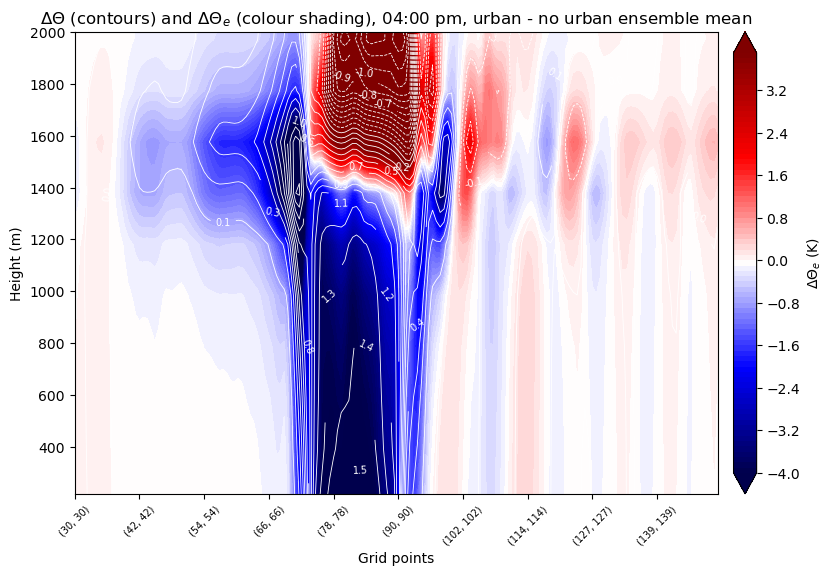

In [6]:
exp0 = '30km'
base_path = "/glade/derecho/scratch/fdemartin/ens/no_urban/"
base_path2 = "/glade/derecho/scratch/fdemartin/ens/30km/"
var = 'theta'
start_time = datetime(2023, 5, 31, 14, 0, 0)
members = range(0, 11)  # ensemble members da 0 a 10 (inclusi)
start_point = CoordPair(x=30, y=30)
end_point   = CoordPair(x=150, y=150)
levels_w = np.arange(-0.5, 0.5, 0.01)
levels_thetae = np.arange(320, 350, 1)
levels_diff = np.arange(-4., 4., 0.1)
levels_diff2 = np.arange(-2, 2, 0.1)

# solo il primo time step
time_str = start_time.strftime("%Y-%m-%d_%H:%M:%S")

theta_cross_list = []
w_cross_list = []

for member in members:
    file_name = f"{base_path}{member}/wrfout_d01_{time_str}"
    file_name2 = f"{base_path2}{member}/wrfout_d01_{time_str}"

    if not os.path.exists(file_name) or not os.path.exists(file_name2):
        print(f"Errore: file non trovato per member {member}")
        continue

    ncfile = Dataset(file_name)
    theta = getvar(ncfile, var, timeidx=0)
    w = getvar(ncfile, 'theta_e', timeidx=0)  # DataArray xarray, con metadata intatta
    z = getvar(ncfile, "z", timeidx=0)        # DataArray xarray

    ncfile2 = Dataset(file_name2)
    theta2 = getvar(ncfile2, var, timeidx=0)
    w2 = getvar(ncfile2, 'theta_e', timeidx=0)
    z2 = getvar(ncfile2, "z", timeidx=0)

    theta_diff = theta2 - theta
    w_diff = w2 - w

    theta_cross = vertcross(theta_diff, z, wrfin=ncfile,
                             start_point=start_point, end_point=end_point,
                             latlon=True, meta=True)
    w_cross = vertcross(w_diff, z, wrfin=ncfile,
                         start_point=start_point, end_point=end_point,
                         latlon=True, meta=True)

    ncfile.close()
    ncfile2.close()

    theta_cross_list.append(theta_cross)
    w_cross_list.append(w_cross)

if len(theta_cross_list) == 0:
    raise RuntimeError("Nessun ensemble member trovato per questo time step.")

# media sugli ensemble members
theta_cross_mean = np.mean([to_np(tc) for tc in theta_cross_list], axis=0)
w_cross_mean = np.mean([to_np(wc) for wc in w_cross_list], axis=0)

# uso il primo cross section come riferimento per le coordinate (uguali per tutti i member)
ref_cross = theta_cross_list[0]
x_ticks = np.arange(ref_cross.shape[-1])
vert_vals = to_np(ref_cross.coords["vertical"])
coord_pairs = to_np(ref_cross.coords["xy_loc"])
x_labels = [f"({pair.x:.0f}, {pair.y:.0f})" for pair in coord_pairs]

fig, ax = plt.subplots(figsize=(10, 6))
cf = ax.contourf(x_ticks, vert_vals, w_cross_mean, levels=levels_diff,
                  cmap="seismic", extend="both")
cb = fig.colorbar(cf, ax=ax, orientation="vertical", pad=0.02)
cb.set_label(r"$\Delta \Theta_e$ (K)")
c1 = ax.contour(x_ticks, vert_vals, theta_cross_mean, levels=levels_diff2,
                 colors="white", linewidths=0.6)
ax.clabel(c1, fmt="%3.1f", fontsize=7, colors='white')
ax.set_ylim(220, 2000)
ax.set_xlabel("Grid points")
ax.set_ylabel("Height (m)")
ax.set_title(rf"$\Delta \Theta$ (contours) and $\Delta \Theta_e$ (colour shading), 04:00 pm, urban - no urban ensemble mean")
thin = max(1, len(x_ticks) // 10)
ax.set_xticks(x_ticks[::thin])
ax.set_xticklabels(x_labels[::thin], rotation=45, fontsize=7)
fig.savefig(f"/glade/u/home/fdemartin/plot/cross_section_thetae_diff_{exp0}_ensmean.png",
            bbox_inches="tight", dpi=300)

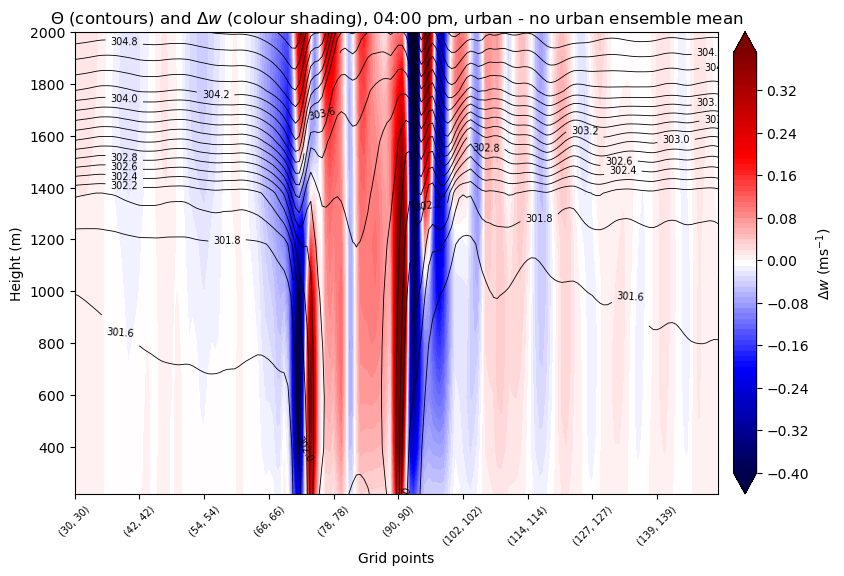

In [5]:
exp0 = '30km'
base_path = "/glade/derecho/scratch/fdemartin/ens/no_urban/"
base_path2 = "/glade/derecho/scratch/fdemartin/ens/30km/"
var = 'theta'
start_time = datetime(2023, 5, 31, 14, 0, 0)
members = range(0, 11)  # ensemble members da 0 a 10 (inclusi)
start_point = CoordPair(x=30, y=30)
end_point   = CoordPair(x=150, y=150)
levels_w = np.arange(-0.5, 0.5, 0.01)
levels_thetae = np.arange(320, 350, 1)
levels_theta = np.arange(295, 320, 0.2)
levels_diff = np.arange(-0.4, 0.4, 0.01)
levels_diff2 = np.arange(-2, 2, 0.1)

# solo il primo time step
time_str = start_time.strftime("%Y-%m-%d_%H:%M:%S")

theta_cross_list = []
w_cross_list = []

for member in members:
    file_name = f"{base_path}{member}/wrfout_d01_{time_str}"
    file_name2 = f"{base_path2}{member}/wrfout_d01_{time_str}"

    if not os.path.exists(file_name) or not os.path.exists(file_name2):
        print(f"Errore: file non trovato per member {member}")
        continue

    ncfile = Dataset(file_name)
    theta = getvar(ncfile, var, timeidx=0)
    w = getvar(ncfile, 'wa', timeidx=0)  # DataArray xarray, con metadata intatta
    z = getvar(ncfile, "z", timeidx=0)        # DataArray xarray

    ncfile2 = Dataset(file_name2)
    theta2 = getvar(ncfile2, var, timeidx=0)
    w2 = getvar(ncfile2, 'wa', timeidx=0)
    z2 = getvar(ncfile2, "z", timeidx=0)

    theta_diff = theta2 - theta
    w_diff = w2 - w

    theta_cross = vertcross(theta2, z, wrfin=ncfile,
                             start_point=start_point, end_point=end_point,
                             latlon=True, meta=True)
    w_cross = vertcross(w_diff, z, wrfin=ncfile,
                         start_point=start_point, end_point=end_point,
                         latlon=True, meta=True)

    ncfile.close()
    ncfile2.close()

    theta_cross_list.append(theta_cross)
    w_cross_list.append(w_cross)

if len(theta_cross_list) == 0:
    raise RuntimeError("Nessun ensemble member trovato per questo time step.")

# media sugli ensemble members
theta_cross_mean = np.mean([to_np(tc) for tc in theta_cross_list], axis=0)
w_cross_mean = np.mean([to_np(wc) for wc in w_cross_list], axis=0)

# uso il primo cross section come riferimento per le coordinate (uguali per tutti i member)
ref_cross = theta_cross_list[0]
x_ticks = np.arange(ref_cross.shape[-1])
vert_vals = to_np(ref_cross.coords["vertical"])
coord_pairs = to_np(ref_cross.coords["xy_loc"])
x_labels = [f"({pair.x:.0f}, {pair.y:.0f})" for pair in coord_pairs]

fig, ax = plt.subplots(figsize=(10, 6))
cf = ax.contourf(x_ticks, vert_vals, w_cross_mean, levels=levels_diff,
                  cmap="seismic", extend="both")
cb = fig.colorbar(cf, ax=ax, orientation="vertical", pad=0.02)
cb.set_label(r"$\Delta w \text{ (ms}^{-1}$)")
c1 = ax.contour(x_ticks, vert_vals, theta_cross_mean, levels=levels_theta,
                 colors="black", linewidths=0.6)
ax.clabel(c1, fmt="%3.1f", fontsize=7, colors='black')
ax.set_ylim(220, 2000)
ax.set_xlabel("Grid points")
ax.set_ylabel("Height (m)")
ax.set_title(rf"$\Theta$ (contours) and $\Delta w$ (colour shading), 04:00 pm, urban - no urban ensemble mean")
thin = max(1, len(x_ticks) // 10)
ax.set_xticks(x_ticks[::thin])
ax.set_xticklabels(x_labels[::thin], rotation=45, fontsize=7)
fig.savefig(f"/glade/u/home/fdemartin/plot/cross_section_w_diff_{exp0}_ensmean.png",
            bbox_inches="tight", dpi=300)

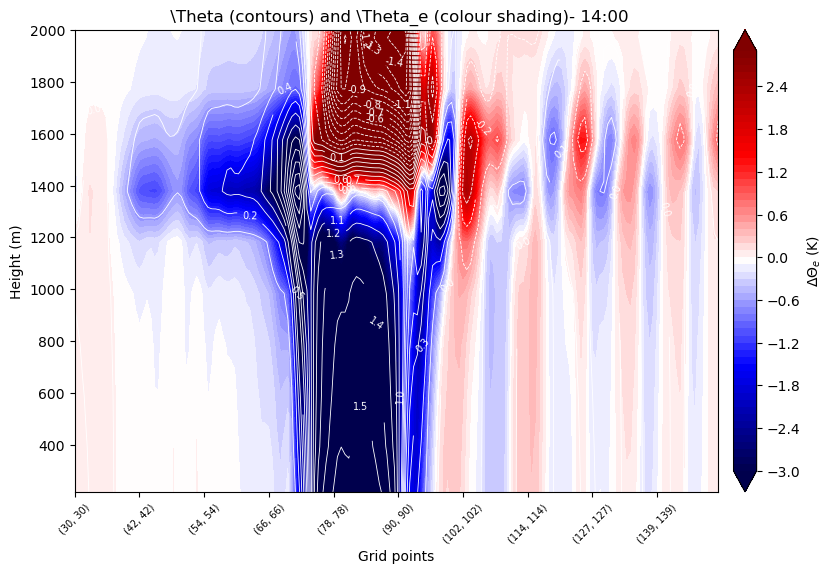

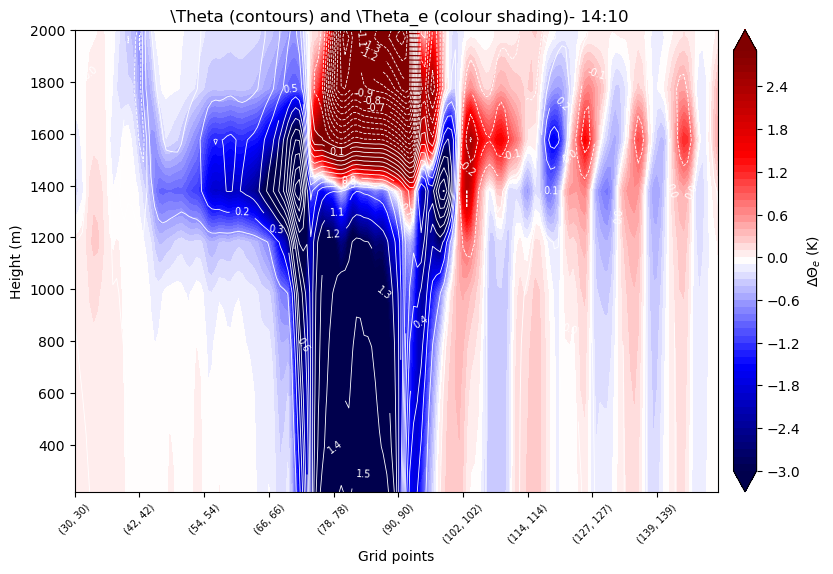

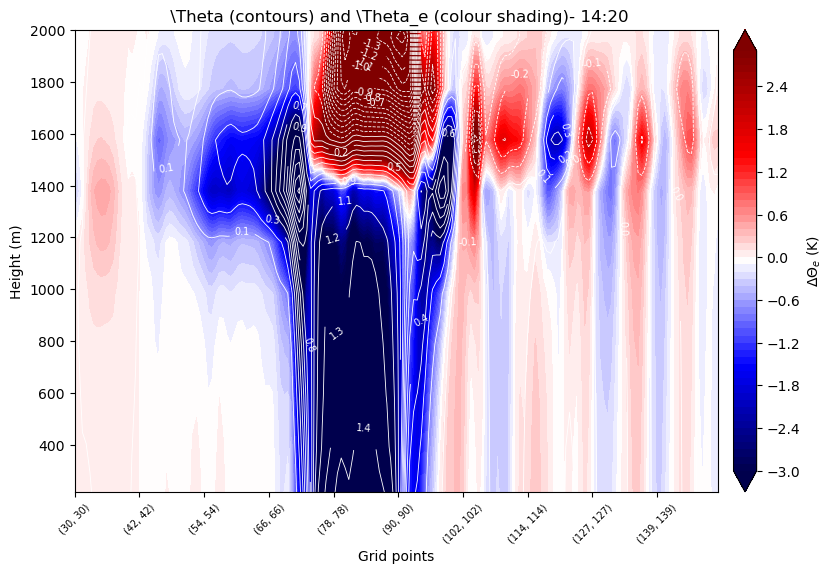

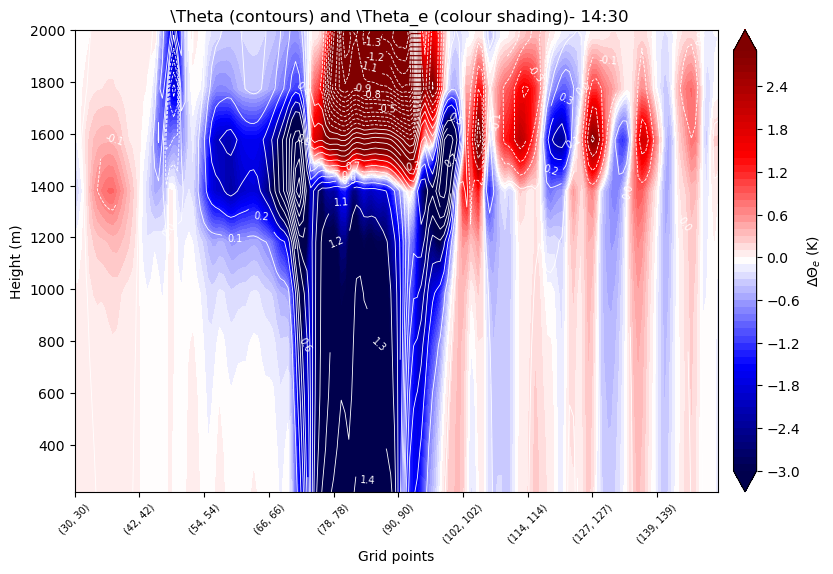

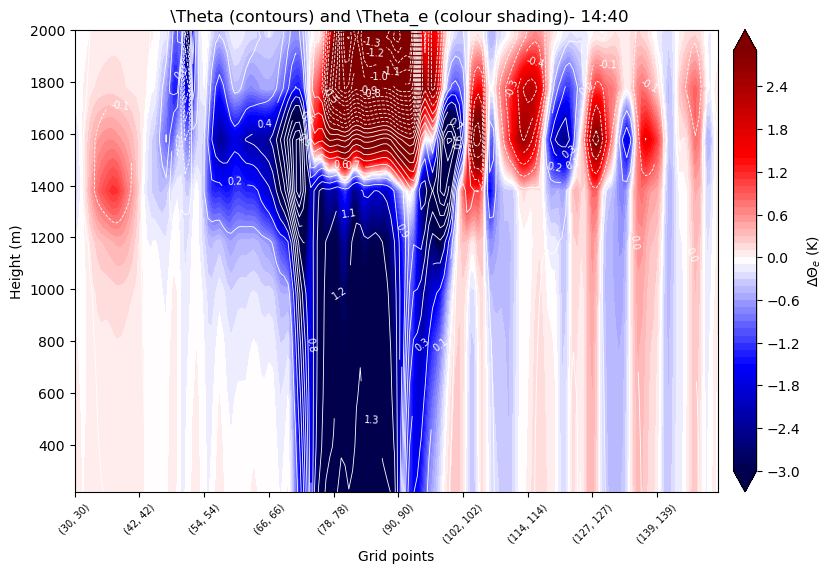

...

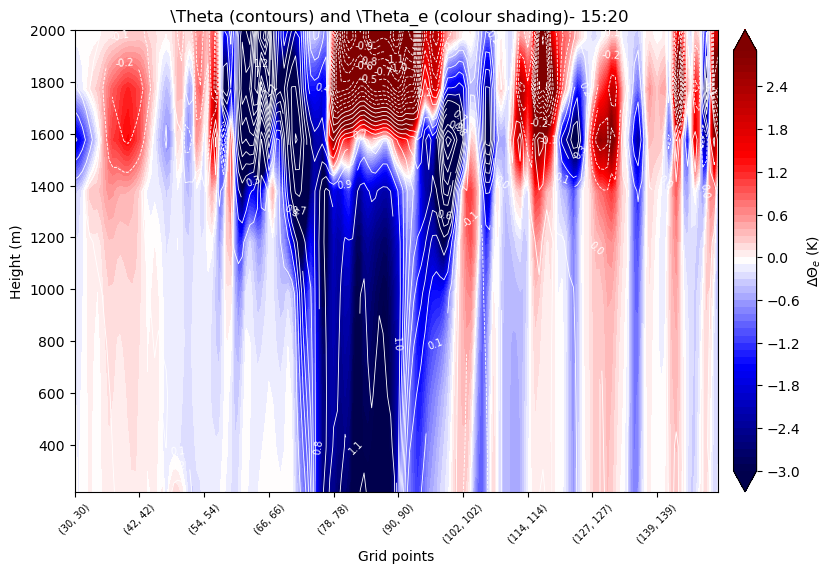

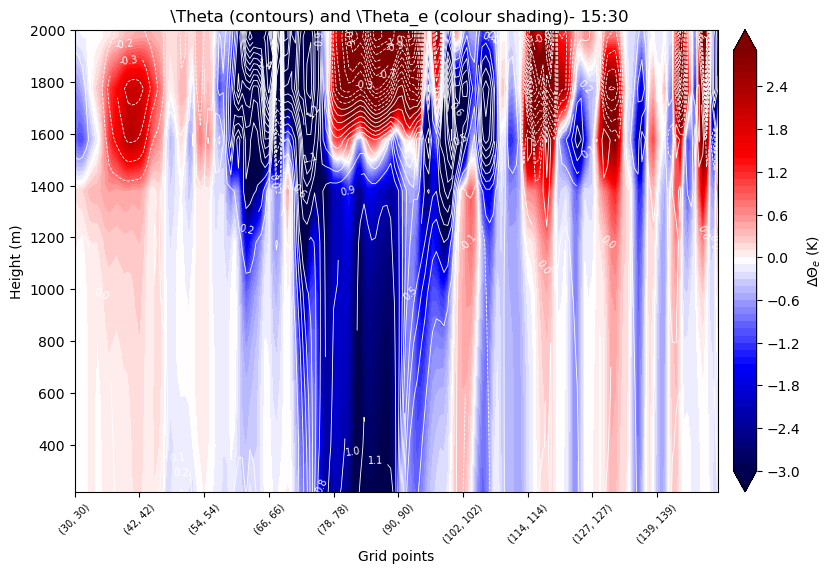

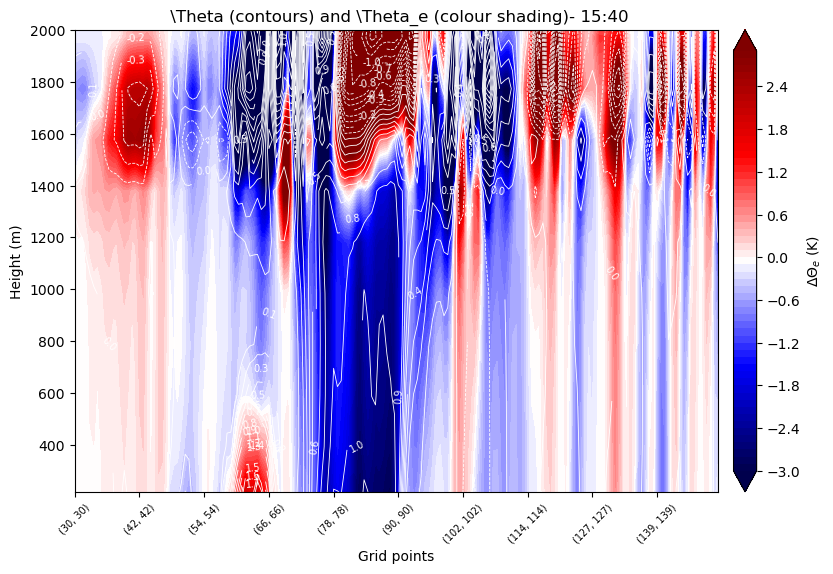

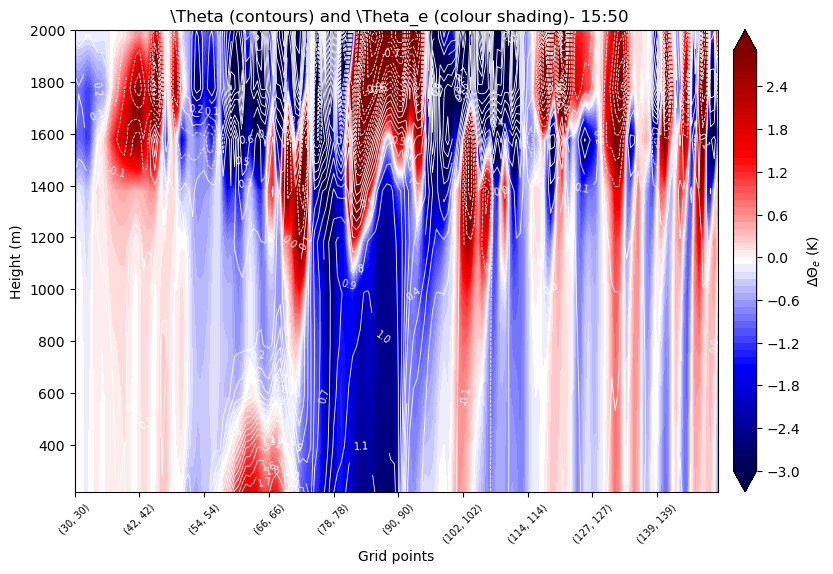

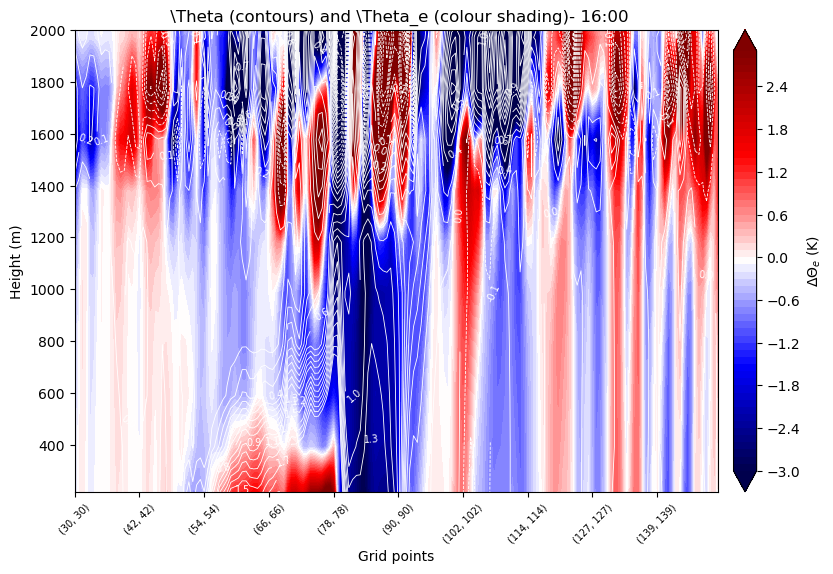

In [2]:
from netCDF4 import Dataset
from wrf import getvar, vertcross, CoordPair, to_np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import numpy as np
import os

exp0 = 'no_urban'
file_path = "/glade/derecho/scratch/fdemartin/ens/no_urban/0/"
file_path2 = "/glade/derecho/scratch/fdemartin/ens/30km/0/"
var = 'theta'

start_time = datetime(2023, 5, 31, 14, 0, 0)
n_steps = 13

start_point = CoordPair(x=30, y=30)
end_point   = CoordPair(x=150, y=150)

levels_w = np.arange(-0.5, 0.5, 0.01)
levels_thetae = np.arange(320, 350, 1)
levels_diff=np.arange(-3, 3, 0.1)
levels_diff2=np.arange(-2, 2, 0.1)

for i in range(n_steps):
    current_time = start_time + timedelta(minutes=10 * i)
    time_str = current_time.strftime("%Y-%m-%d_%H:%M:%S")
    file_name = f"{file_path}/wrfout_d01_{time_str}"
    file_name2 = f"{file_path2}/wrfout_d01_{time_str}"
    if not os.path.exists(file_name):
        print(f"Errore: file non trovato -> {file_name}")
        continue

    ncfile = Dataset(file_name)
    theta = getvar(ncfile, var, timeidx=0)
    w = getvar(ncfile, 'theta_e', timeidx=0)# DataArray xarray, con metadata intatta
    z = getvar(ncfile, "z", timeidx=0)      # DataArray xarray
    
    ncfile2 = Dataset(file_name2)
    theta2 = getvar(ncfile2, var, timeidx=0)
    w2 = getvar(ncfile2, 'theta_e', timeidx=0)# DataArray xarray, con metadata intatta
    z2 = getvar(ncfile2, "z", timeidx=0) 

    theta_diff=theta2-theta
    w_diff=w2-w

    theta_cross = vertcross(theta_diff, z, wrfin=ncfile,
                             start_point=start_point, end_point=end_point,
                             latlon=True, meta=True)
    w_cross = vertcross(w_diff, z, wrfin=ncfile,
                         start_point=start_point, end_point=end_point,
                         latlon=True, meta=True)

    ncfile.close()

    x_ticks = np.arange(theta_cross.shape[-1])
    vert_vals = to_np(theta_cross.coords["vertical"])
    coord_pairs = to_np(theta_cross.coords["xy_loc"])
    x_labels = [f"({pair.x:.0f}, {pair.y:.0f})" for pair in coord_pairs]

    fig, ax = plt.subplots(figsize=(10, 6))

    cf = ax.contourf(x_ticks, vert_vals, to_np(w_cross), levels=levels_diff,
                      cmap="seismic", extend="both")
    cb = fig.colorbar(cf, ax=ax, orientation="vertical", pad=0.02)
    cb.set_label("$\Delta \Theta_e$ (K)")

    c1 = ax.contour(x_ticks, vert_vals, to_np(theta_cross), levels=levels_diff2,
                     colors="white", linewidths=0.6)
    ax.clabel(c1, fmt="%3.1f", fontsize=7,colors='white')

    ax.set_ylim(220, 2000)
    ax.set_xlabel("Grid points")
    ax.set_ylabel("Height (m)")
    ax.set_title(rf" \Theta (contours) and \Theta_e (colour shading)- {current_time.strftime('%H:%M')}")

    thin = max(1, len(x_ticks) // 10)
    ax.set_xticks(x_ticks[::thin])
    ax.set_xticklabels(x_labels[::thin], rotation=45, fontsize=7)

    fig.savefig(f"/glade/u/home/fdemartin/plot/cross_section_thetae_diff_{exp0}_{i:02d}.png",
                bbox_inches="tight", dpi=200)
    #plt.close(fig)

In [ ]:
from netCDF4 import Dataset
from wrf import getvar, vertcross, CoordPair, to_np
import matplotlib.pyplot as plt
import numpy as np

file_name = f"{file_path}/wrfout_d01_2023-05-31_14:00:00"
ncfile = Dataset(file_name)

# Campo 3D di temperatura potenziale e quota geopotenziale (serve come coordinata verticale)
theta = getvar(ncfile, "theta", timeidx=0)
z = getvar(ncfile, "z", timeidx=0)

# Definisci la linea della cross section in indici di griglia (x, y)
# In alternativa puoi usare lat/lon: CoordPair(lat=..., lon=...) con latlon=True
start_point = CoordPair(x=50, y=125)
end_point   = CoordPair(x=200, y=125)

theta_cross = vertcross(theta, z, wrfin=ncfile,
                         start_point=start_point, end_point=end_point,
                         latlon=True, meta=True)

# Coordinate per gli assi
x_ticks = np.arange(theta_cross.shape[-1])
vert_vals = to_np(theta_cross.coords["vertical"])   # quote in metri
coord_pairs = to_np(theta_cross.coords["xy_loc"])
x_labels = [pair.latlon_str() for pair in coord_pairs]

fig, ax = plt.subplots(figsize=(10, 6))

levels = np.arange(295, 330, 1)
cf = ax.contourf(x_ticks, vert_vals, to_np(theta_cross), levels=levels,
                  cmap="viridis", extend="both")
cb = fig.colorbar(cf, ax=ax, orientation="vertical", pad=0.02)
cb.set_label("Temperatura potenziale (K)")

# Contour line più diradati sopra il filled, con etichette
c1 = ax.contour(x_ticks, vert_vals, to_np(theta_cross), levels=np.arange(295, 330, 2),
                 colors="black", linewidths=0.6)
ax.clabel(c1, fmt="%3.0f", fontsize=7)

ax.set_ylim(0, 3000)   # limita ai bassi livelli, dove si vede meglio il cold pool
ax.set_xlabel("Distanza lungo la linea")
ax.set_ylabel("Altezza (m)")
ax.set_title("Cross section - Temperatura potenziale")

thin = max(1, len(x_ticks) // 10)
ax.set_xticks(x_ticks[::thin])
ax.set_xticklabels(x_labels[::thin], rotation=45, fontsize=7)

fig.savefig("/glade/u/home/fdemartin/plot/cross_section_theta.png",
            bbox_inches="tight", dpi=200)

In [9]:
exp0='no_urban'
exp1="30km"
var='W'
level=25

file_path="/glade/derecho/scratch/fdemartin/ens/no_urban/0/"

x=np.arange(0,250,1)
y=np.arange(0,250,1)

# Impostazioni temporali
start_time = datetime(2023, 5, 31, 14, 0, 0)
n_steps = 13  # 120 minuti / 10 min = 12 intervalli + 1 file iniziale
cape=np.zeros([n_steps,250,250])

for i in range(n_steps):
    # Calcola l'orario corrente per ogni iterazione
    current_time = start_time + timedelta(minutes=10 * i)
    # Formatta la stringa della data come richiesto da WRF (YYYY-MM-DD_HH:mm:ss)
    time_str = current_time.strftime("%Y-%m-%d_%H:%M:%S")
    # Costruisci il percorso del file
    # Nota: ho mantenuto la tua struttura file_path+str(i) 
    file_name = f"{file_path}/wrfout_d01_{time_str}"
    try:
        ncfile = Dataset(file_name)
        # Estrazione SLP (Sea Level Pressure)
        # Assicurati che 'cape' sia pre-allocato correttamente con shape (13, lat, lon)
        cape[i, :, :] = to_np(getvar(ncfile, var, timeidx=0))[level,:,:]
        ncfile.close() # Buona pratica chiudere il file
    except FileNotFoundError:
        print(f"Errore: file non trovato -> {file_name}")

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

file_path="/glade/derecho/scratch/fdemartin/ens/30km/0/"

cape2=np.zeros([n_steps,250,250])

ncfile = Dataset(file_path+"/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

for i in range(n_steps):
    # Calcola l'orario corrente per ogni iterazione
    current_time = start_time + timedelta(minutes=10 * i)
    # Formatta la stringa della data come richiesto da WRF (YYYY-MM-DD_HH:mm:ss)
    time_str = current_time.strftime("%Y-%m-%d_%H:%M:%S")
    # Costruisci il percorso del file
    # Nota: ho mantenuto la tua struttura file_path+str(i) 
    file_name = f"{file_path}/wrfout_d01_{time_str}"
    try:
        ncfile = Dataset(file_name)
        # Estrazione SLP (Sea Level Pressure)
        # Assicurati che 'cape' sia pre-allocato correttamente con shape (13, lat, lon)
        cape2[i, :, :] = to_np(getvar(ncfile, var, timeidx=0))[level,:,:]
        ncfile.close() # Buona pratica chiudere il file
    except FileNotFoundError:
        print(f"Errore: file non trovato -> {file_name}")

diff=cape2-cape

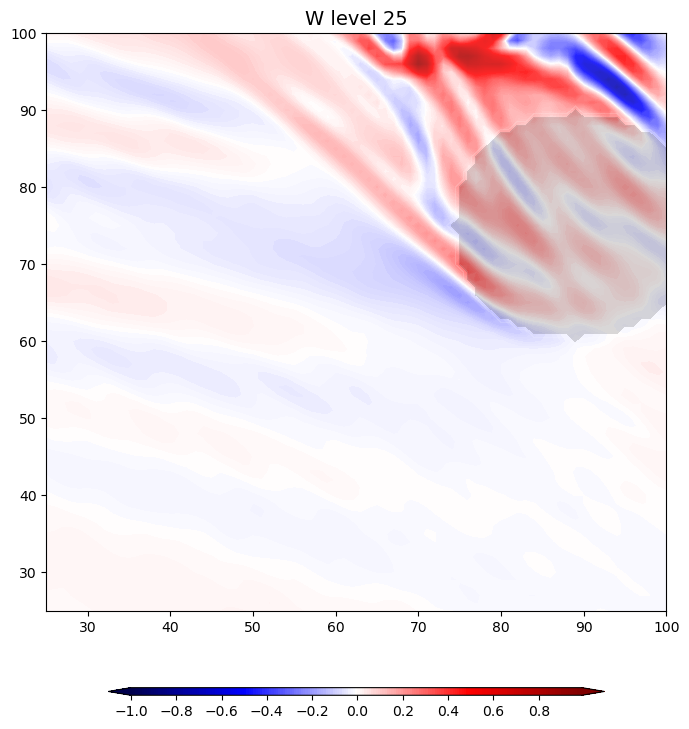

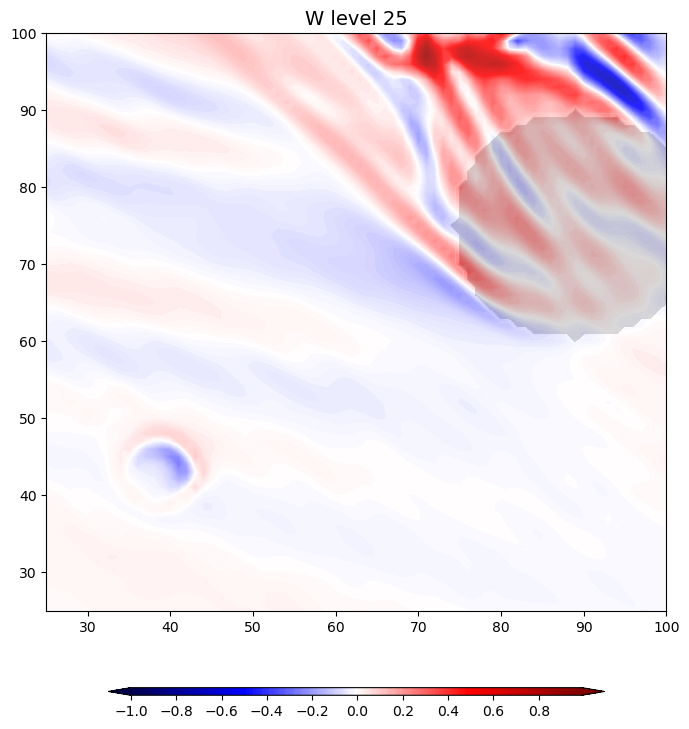

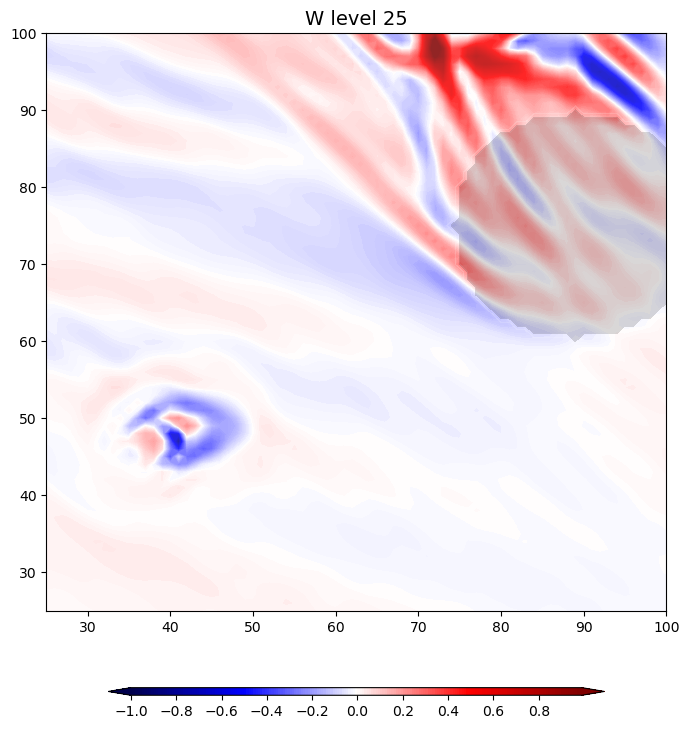

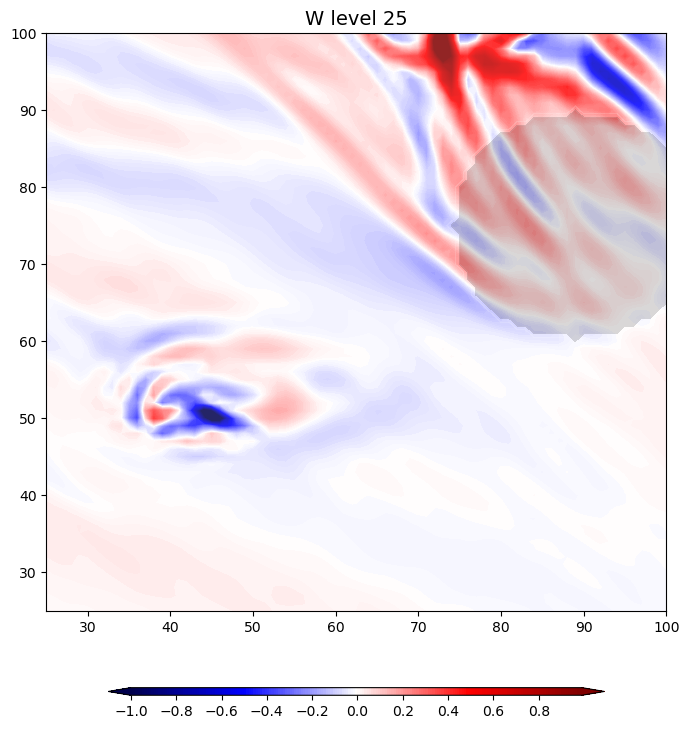

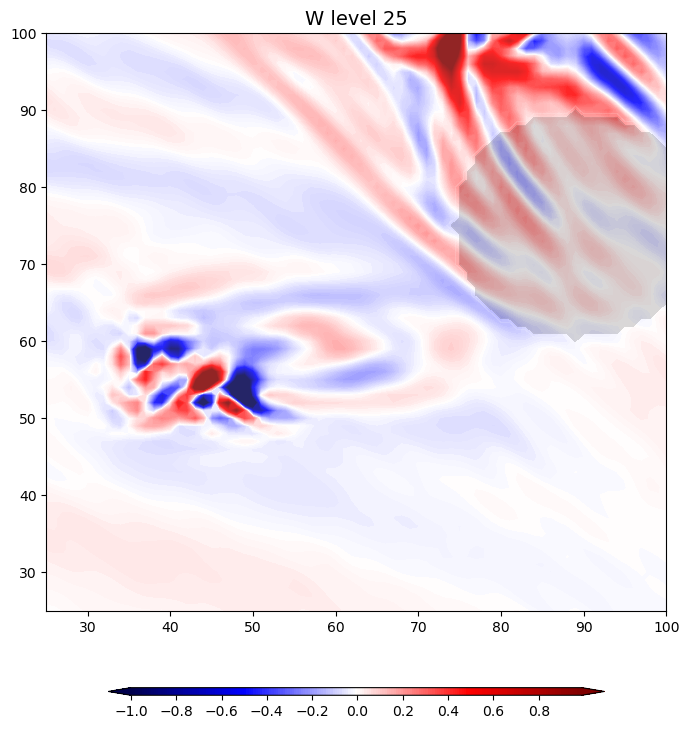

...

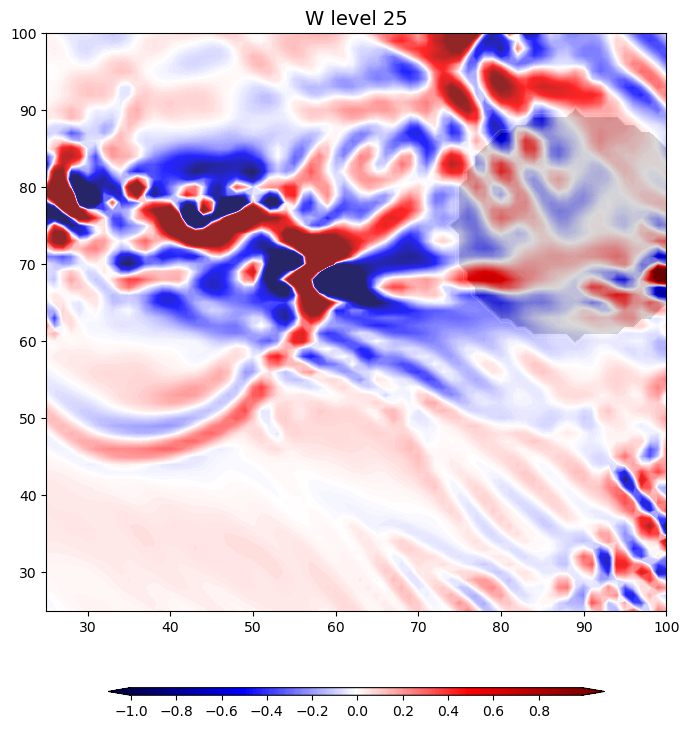

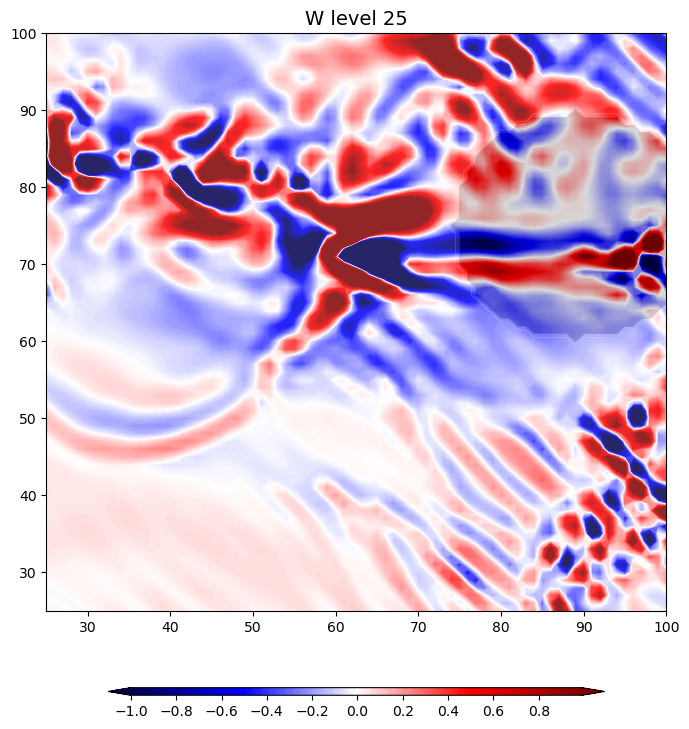

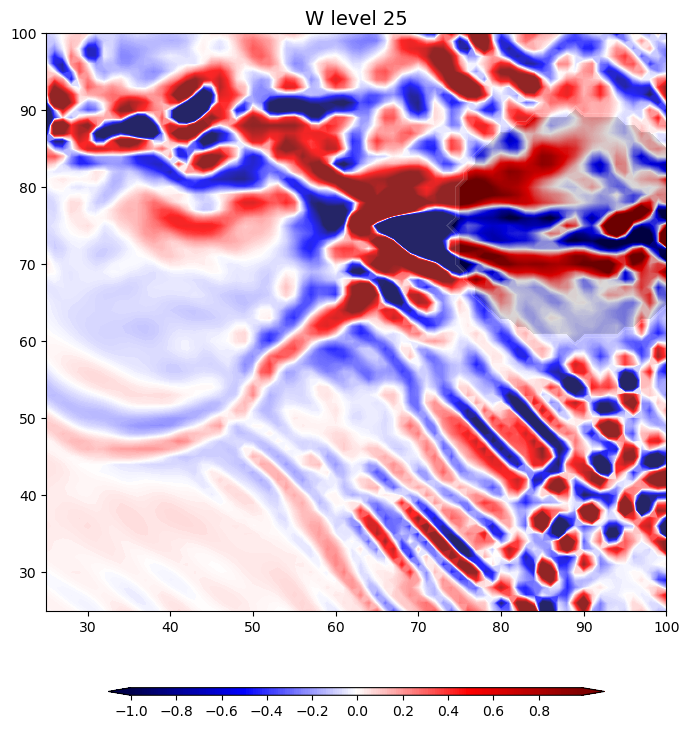

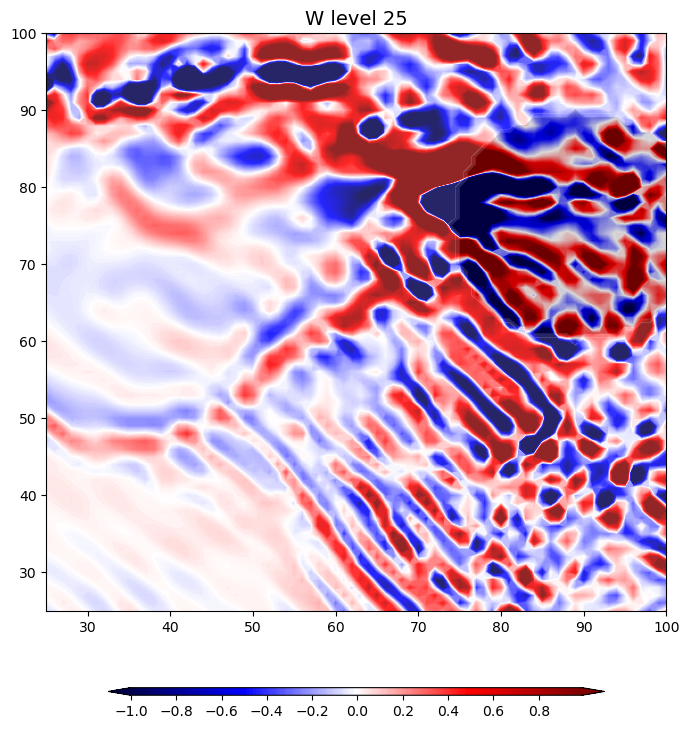

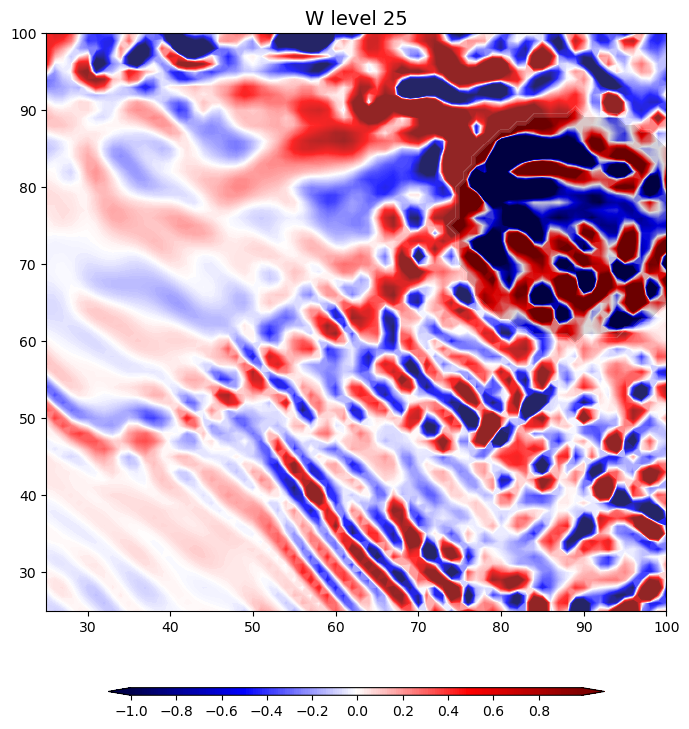

In [11]:
levels=np.arange(-1,1,0.01)

for i in range(n_steps):
    fig = plt.figure(figsize=(8, 10))
    #print(str(times[i,0])[11:16])
    ax = fig.add_subplot(1, 1, 1)
    ax.set_title(f'{var} level {level}',fontsize=14)
    ax.set_ylim(25,100)
    ax.set_xlim(25,100)
    # MSLP in contours and min max
    #c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
    #ax.clabel(c1,fmt='%4.1i',fontsize=10)
    #cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
    cf = ax.contourf(x, y, diff[i,:,:], levels=levels, cmap='seismic', extend='both')
    gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
    #gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
    cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
    n=5
    #q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
    #plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')
    
    #for i in range(0,11):
        #ax.plot(xt[i,:],yt[i,:],'k-')
    figname=f'/glade/u/home/fdemartin/plot/review/{var}_{level}_{i}'
    fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [4]:
file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

u=np.zeros([11,63,250,250])
v=np.zeros([11,63,250,250])
w=np.zeros([11,63,250,250])
t=np.zeros([11,63,250,250])
p=np.zeros([11,63,250,250])
qvapor=np.zeros([11,63,250,250])

eps=0.622
Rd=287.052874
#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    print(i)
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p[i,:,:,:]= to_np(getvar(ncfile, 'pres',timeidx=0,units='Pa'))#[:,:]
    qvapor[i,:,:,:] = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))#[:,:]
    t[i,:,:,:] = to_np(getvar(ncfile, 'temp',timeidx=0,units='K'))#[:,:]
    
    u[i,:,:,:] = to_np(getvar(ncfile, 'ua',timeidx=0))
    v[i,:,:,:] = to_np(getvar(ncfile, 'va',timeidx=0))
    w[i,:,:,:] = to_np(getvar(ncfile, 'wa',timeidx=0))
    
u=np.mean(u,axis=0)
v=np.mean(v,axis=0)
w=np.mean(w,axis=0)
qvapor=np.mean(qvapor,axis=0)
t=np.mean(t,axis=0)
p=np.mean(p,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

u2=np.zeros([11,63,250,250])
v2=np.zeros([11,63,250,250])
w2=np.zeros([11,63,250,250])
t2=np.zeros([11,63,250,250])
p2=np.zeros([11,63,250,250])
qvapor2=np.zeros([11,63,250,250])
pprime=np.zeros([11,63,250,250])

for i in range(0,11):
    print(i)
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p2[i,:,:,:] = to_np(getvar(ncfile, 'pres',timeidx=0,units='Pa'))
    #pprime[i,:,:,:] = to_np(getvar(ncfile, 'P'))#[:,:]
    qvapor2[i,:,:,:] = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))#[:,:]
    t2[i,:,:,:] = to_np(getvar(ncfile, 'temp',timeidx=0,units='K'))#[:,:]
    u2[i,:,:,:] = to_np(getvar(ncfile, 'ua',timeidx=0))#[0,:,:]
    v2[i,:,:,:] = to_np(getvar(ncfile, 'va',timeidx=0))#[0,:,:]
    w2[i,:,:,:] = to_np(getvar(ncfile, 'wa',timeidx=0))#[0,:,:]
    
u2=np.mean(u2,axis=0)
v2=np.mean(v2,axis=0)
w2=np.mean(w2,axis=0)
qvapor2=np.mean(qvapor2,axis=0)
t2=np.mean(t2,axis=0)
p2=np.mean(p2,axis=0)
#pprime=np.mean(pprime,axis=0)

0
1
2
3
4
5
6
7
8
9
10
0
1
2
3
4
5
6
7
8
9
10


In [5]:
ncfile = Dataset(file_path+"10/wrfout_d01_2023-05-31_14:00:00")
z = to_np(getvar(ncfile, 'geopt',timeidx=0))/9.81#[:,:]

rho=(mpcalc.density(p*units.Pa,t*units.K,qvapor*units("kg/kg"))).magnitude
rho2=(mpcalc.density(p2*units.Pa,t2*units.K,qvapor2*units("kg/kg"))).magnitude
#print(np.shape(rho))
#rho_m=np.zeros([63,250,250])

#for i in range(0,63):
#    rho[i,:,:]=np.mean(rho[i,:,:],axis=(0,1))

#rho=rho_m
p_prime=p2-p

#rho=eps*p(1+qvapor)/(Rd*t(qvapor+eps))
#rho2=eps*p(1+qvapor2)/(Rd*t2(qvapor2+eps2))

rho_prime=rho2-rho
B=rho_prime/rho*9.81
delta_z=z[1:,:,:]-z[:-1,:,:]

#print(z[:,0,0],delta_z[:,0,0])

Buoyancy_term=-(mpcalc.first_derivative(f=B*rho, axis=0, x=z))

exner0=mpcalc.exner_function((p)*units.Pa)
exner=mpcalc.exner_function(p2*units.Pa)

print(exner[:,0,0])
print(exner0[:,0,0])

Dynamic_term1=(mpcalc.first_derivative(u2,axis=1,delta=1000))**2+(mpcalc.first_derivative(v2,axis=2,delta=1000))**2+(mpcalc.first_derivative(w2,axis=0,x=z))**2
Dynamic_term2a=mpcalc.first_derivative(v2,axis=1,delta=1000)*mpcalc.first_derivative(u2,axis=2,delta=1000)
Dynamic_term2b=mpcalc.first_derivative(w2,axis=1,delta=1000)*mpcalc.first_derivative(u2,axis=0,x=z)
Dynamic_term2c=mpcalc.first_derivative(w2,axis=2,delta=1000)*mpcalc.first_derivative(v2,axis=0,x=z)
Dynamic_term=-(-Dynamic_term1-2*Dynamic_term2a-2*Dynamic_term2b-2*Dynamic_term2c)*rho

Dynamic_term.magnitude.astype('float64').tofile('dynamic.bin',format='f')

#Buoyancy_term=np.transpose(Buoyancy_term)
Buoyancy_term.magnitude.astype('float64').tofile('forcing.bin',format='f')
#exner=np.transpose(exner)
exner0.magnitude.astype('float64').tofile('exner0.bin',format='f')
exner.magnitude.astype('float64').tofile('exner.bin',format='f')
#z=np.transpose(z)
#print(z[0,0,:])
#z = np.asfortranarray(z)
z.astype('float64').tofile('z.bin',format='f')

# with open("z.bin", "wb") as f:
#     z.astype('float64').tofile(f)

#z_f = np.transpose(z, (1, 0, 2))  # Fortran will see i,j,k
# with open("z.bin", "wb") as f:
#     z.astype('float64').tofile(f)
    
# Riempiamo con un pattern noto per debug

# counter = 1.0
# for k in range(nz):
#     for j in range(ny):
#         for i in range(nx):
#             z1[i, j, k] = counter
#             counter += 1.0

# # Scrittura su file binario in modo compatibile con Fortran
# with open("z.bin", "wb") as f:
#     for k in range(nz):
#         # Transpose (i,j) → (j,i) per scrivere in ordine colonna → riga
#         f.write(z[:, :, k].T.tobytes())    
        
print(np.max(Buoyancy_term))
#print(z_f[0,0,:])

# lhs=mpcalc.laplacian(p_prime,deltas=[delta_z,1000,1000])/rho

[1.0045893886319328 1.0042223450340904 1.0038018935854043 1.0033209416882762 1.002771525420359 1.0021449066056642 1.0014311291569775 1.0006190925915561 0.9996962401994768 0.9986489108915725 0.9974618376573351 0.9961181752684651 0.994599495871977 0.9928852828686788 0.9909534295211659 0.9887800922051794 0.9863395165902259 0.9836042221418559 0.9805452947981763 0.9771321951168921 0.9733337674629762 0.9691184692381644 0.9644548889213594 0.9593139495200717 0.9536736927435409 0.9475086532721687 0.9407880591531758 0.9334893385995106 0.9255967171093589 0.9171001166635004 0.9079955361651698 0.8982854009813391 0.8879790345407588 0.877093027058945 0.8656503773995449 0.8536804382869948 0.841218513967073 0.8283050690273919 0.8149845086659377 0.8013042218794207 0.7873063152193241 0.7730038617979412 0.7584086149405185 0.7435575835509952 0.7284891617128324 0.7132410697418833 0.697849944437836 0.6823503223749777 0.6667758020270531 0.6511573387010889 0.6355246620729162 0.6199060999284381 0.60432713265425

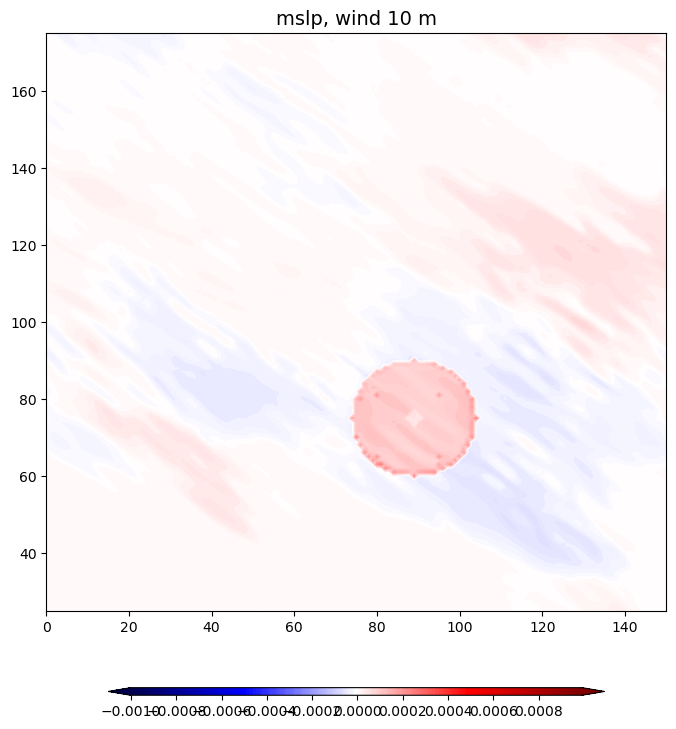

In [6]:
levels=np.arange(-0.001,0.001,0.00001)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('mslp, wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
x=np.arange(0,250,1)
y=np.arange(0,250,1)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, Buoyancy_term[0,:,:], levels=levels, cmap='seismic', extend='both')
#gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
#q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
#plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

#for i in range(0,11):
    #ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/mslp'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

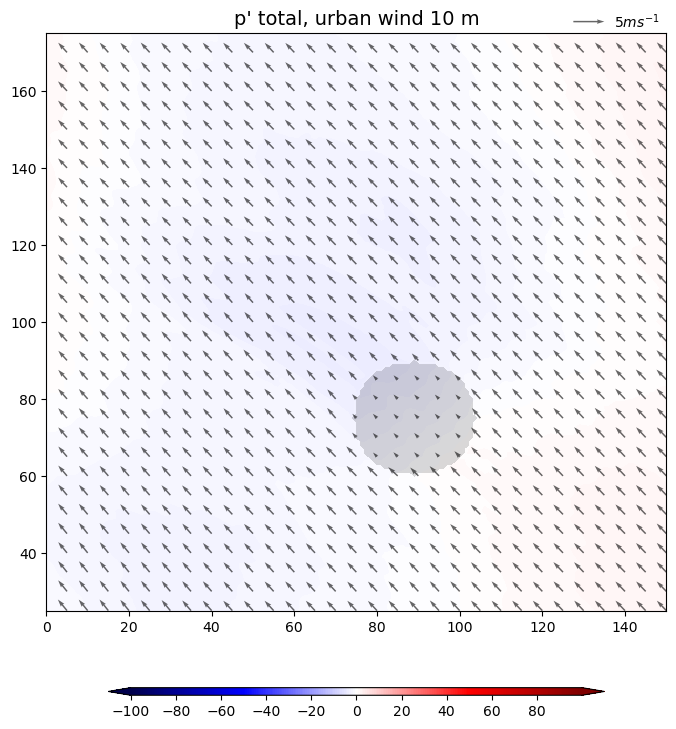

In [7]:
levels=np.arange(-100,100,0.1)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title("p' total, urban wind 10 m",fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, p_prime[10,:,:], levels=levels, cmap='seismic', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

#for i in range(0,11):
    #ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/p_prime_10_nourbanMi_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

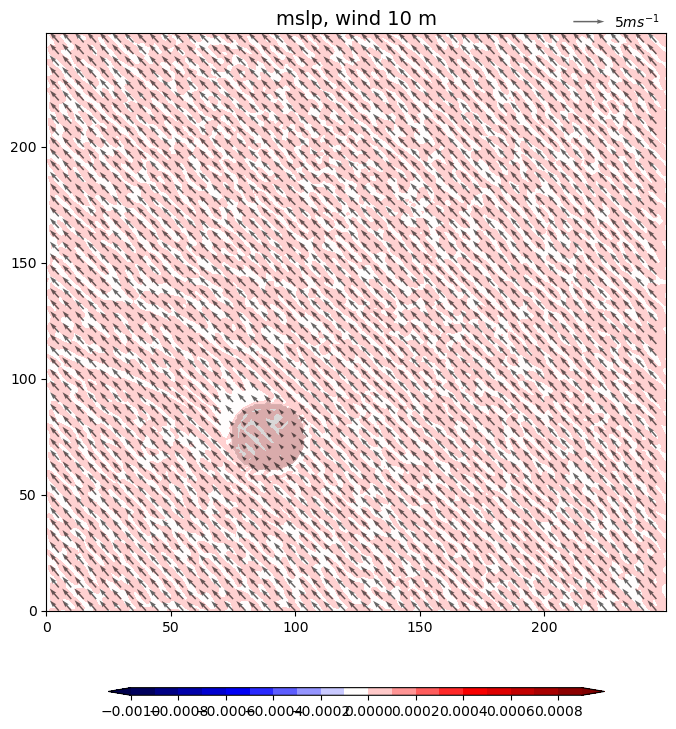

In [8]:
levels=np.arange(-0.001,0.001,0.0001)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('mslp, wind 10 m',fontsize=14)
#ax.set_ylim(25,175)
#ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, Dynamic_term[10,:,:], levels=levels, cmap='seismic', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

#for i in range(0,11):
    #ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/mslp0'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

(250, 250, 63)
0.060577540521916905


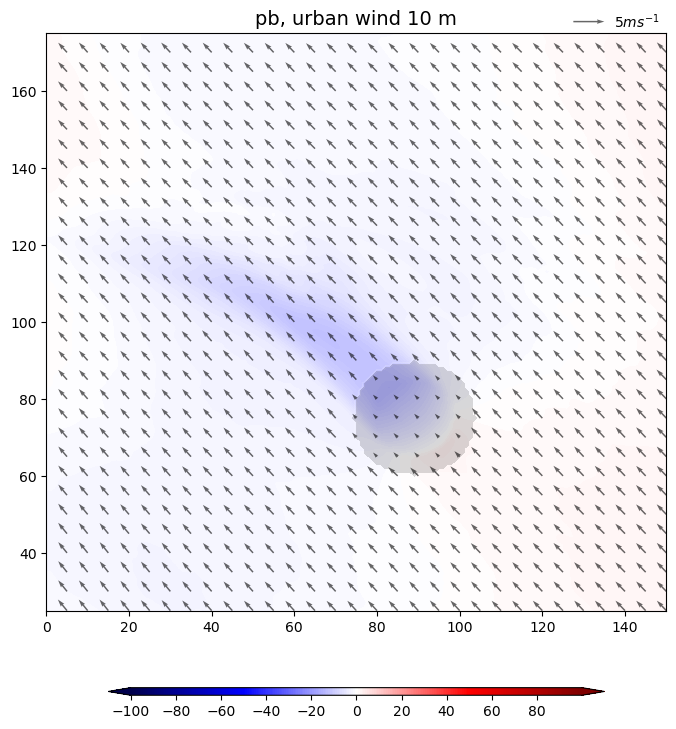

In [9]:
#u_3d = u.value.reshape((nx, ny, nz)).transpose(2, 1, 0)

pb = np.fromfile('/glade/u/home/fdemartin/pb.bin', dtype=np.float64)  # Usa float64 se in Fortran usavi "double precision"

nx,ny,nz=250,250,63

# Ricostruisce la forma con ordine Fortran
pb = np.reshape(pb, (nx, ny, nz), order='F')
pb = np.transpose(pb, (1, 0, 2))  # Fortran will see i,j,k
print(np.shape(pb))

print(np.mean(pb))
#pb=pb-np.mean(pb)
#print(Buoyancy_term)
#diffp=p2-p
#levels=np.arange(-100,100,0.1)
#levels=np.arange(-0.0001,0.0001,0.000001)

x=np.arange(0,250,1)
y=np.arange(0,250,1)
levels=np.arange(-100,100,0.1)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('pb, urban wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)

# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, pb[:,:,10], cmap='seismic', extend='both',levels=levels)
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(p_prime[1,:,:]), levels=[-200,-100,0,100,200], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

figname='/glade/u/home/fdemartin/plot/env_diff/pb_10'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

(250, 250, 63)


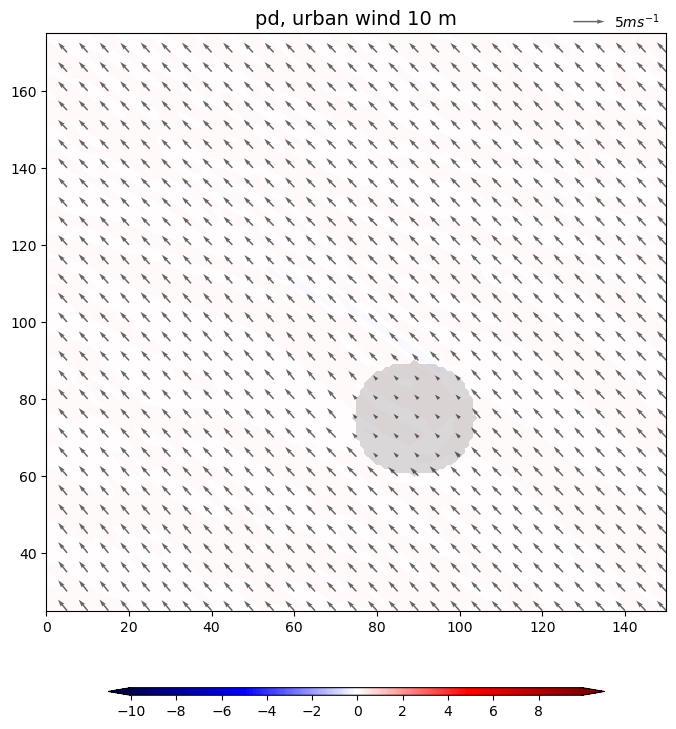

In [10]:

#u_3d = u.value.reshape((nx, ny, nz)).transpose(2, 1, 0)

pd = np.fromfile('/glade/u/home/fdemartin/pd.bin', dtype=np.float64)  # Usa float64 se in Fortran usavi "double precision"

nx,ny,nz=250,250,63

# Ricostruisce la forma con ordine Fortran
pd = np.reshape(pd, (nx, ny, nz), order='F')
pd = np.transpose(pd, (1, 0, 2))  # Fortran will see i,j,k
print(np.shape(pd))

#pd=np.transpose(p_prime,(1,2,0))-pb

#print(Buoyancy_term)
#diffp=p2-p
#levels=np.arange(-100,100,0.1)
#levels=np.arange(-0.0001,0.0001,0.000001)

x=np.arange(0,250,1)
y=np.arange(0,250,1)
levels=np.arange(-10,10,0.1)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('pd, urban wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)

# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, pd[:,:,10], cmap='seismic', extend='both',levels=levels)
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(p_prime[1,:,:]), levels=[-200,-100,0,100,200], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

figname='/glade/u/home/fdemartin/plot/env_diff/pd_10'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

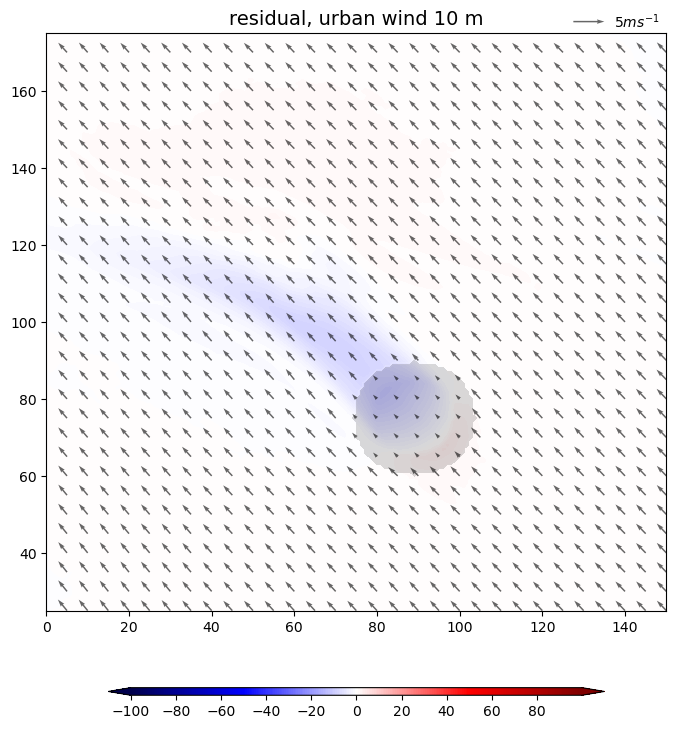

In [11]:
#u_3d = u.value.reshape((nx, ny, nz)).transpose(2, 1, 0)

diff=(pd[:,:,10]+pb[:,:,10])-np.transpose(p_prime,(1,2,0))[:,:,10]

#print(Buoyancy_term)
#diffp=p2-p
#levels=np.arange(-100,100,0.1)
#levels=np.arange(-0.0001,0.0001,0.000001)

x=np.arange(0,250,1)
y=np.arange(0,250,1)
levels=np.arange(-100,100,0.1)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('residual, urban wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)

# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, diff, cmap='seismic', extend='both',levels=levels)
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(p_prime[1,:,:]), levels=[-200,-100,0,100,200], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

figname='/glade/u/home/fdemartin/plot/env_diff/residual_pprime_10'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

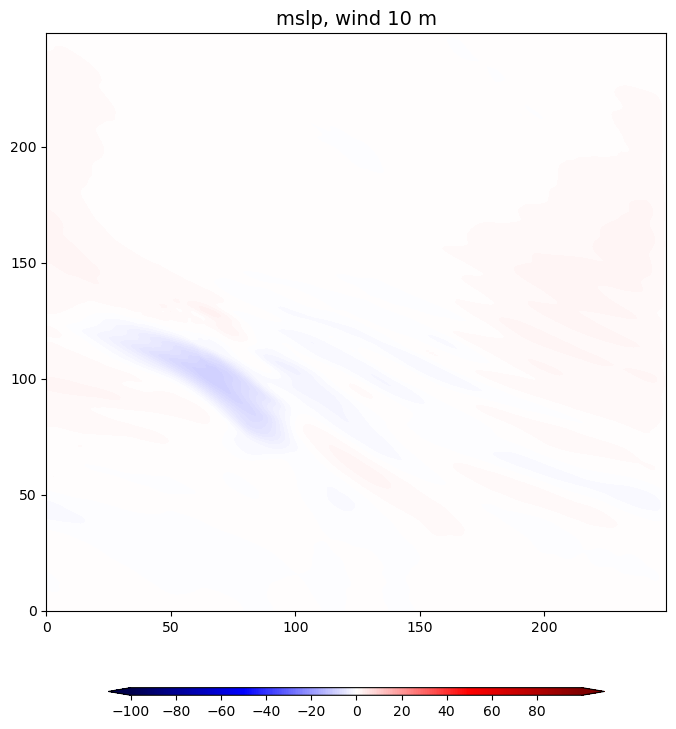

In [12]:
#u_3d = u.value.reshape((nx, ny, nz)).transpose(2, 1, 0)

diff=(pd[:,:,30]+pb[:,:,30])

#print(Buoyancy_term)
#diffp=p2-p
#levels=np.arange(-100,100,0.1)
#levels=np.arange(-0.0001,0.0001,0.000001)

x=np.arange(0,250,1)
y=np.arange(0,250,1)
levels=np.arange(-100,100,0.1)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('mslp, wind 10 m',fontsize=14)
#ax.set_ylim(25,175)
#ax.set_xlim(0,150)

# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, diff, cmap='seismic', extend='both',levels=levels)
#gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(p_prime[1,:,:]), levels=[-200,-100,0,100,200], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
#q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
#plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

figname='/glade/u/home/fdemartin/plot/env_diff/buoyancy'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

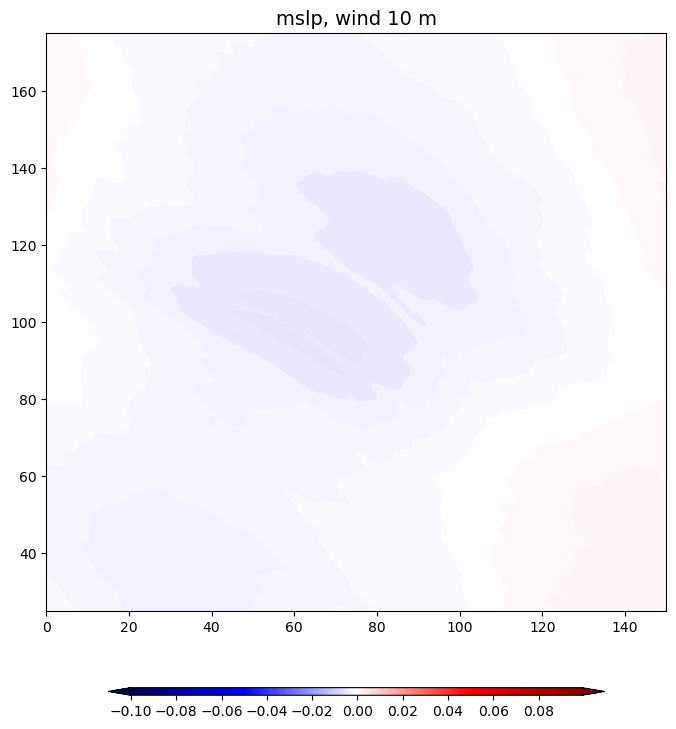

In [13]:
#print(Buoyancy_term)
#diffp=p2-p
#levels=np.arange(-100,100,0.1)
levels=np.arange(-0.1,0.1,0.001)
x=np.arange(0,250,1)
y=np.arange(0,250,1)
#levels=np.arange(-0.000001,0.000001,0.00000001)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('mslp, wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, B[5,:,:], levels=levels, cmap='seismic', extend='both')
#gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
#q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
#plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')

figname='/glade/u/home/fdemartin/plot/env_diff/buoyancy'
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [38]:
file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape[i,:,:] = to_np(getvar(ncfile, 'cape2d',timeidx=0))[0,:,:]

cape=np.mean(cape,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

cape2=np.zeros([11,250,250])

ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape2[i,:,:] = to_np(getvar(ncfile, 'cape2d',timeidx=0))[0,:,:]

cape2=np.mean(cape2,axis=0)

diff=cape2-cape

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

ua2=np.zeros([11,250,250])
va2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    ua2[i,:,:],va2[i,:,:] = to_np(getvar(ncfile, 'uvmet10',timeidx=0))#[:,:]
    #cape2[i,:,:] = interplevel(wa, p, 950)

ua2=np.mean(ua2,axis=0)
va2=np.mean(va2,axis=0)

In [15]:
import pandas as pd
exp=exp1
xt=np.zeros([11,38])
yt=np.zeros([11,38])
for i in range (0,11):
    latlon = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/track_"+str(exp)+"_"+str(i)+".csv")
    #print(latlon['x'].values)
    xt[i,:]=np.array(latlon['x'].values)
    yt[i,:]=latlon['y'].values
    
xm=np.mean(xt,axis=0)
ym=np.mean(yt,axis=0)
xm = xm[~np.isnan(xm)]
ym = ym[~np.isnan(ym)]
print(xm,ym)

FileNotFoundError: [Errno 2] No such file or directory: '/glade/u/home/fdemartin/SPOUT/tracks/track_press_dyn_0.csv'

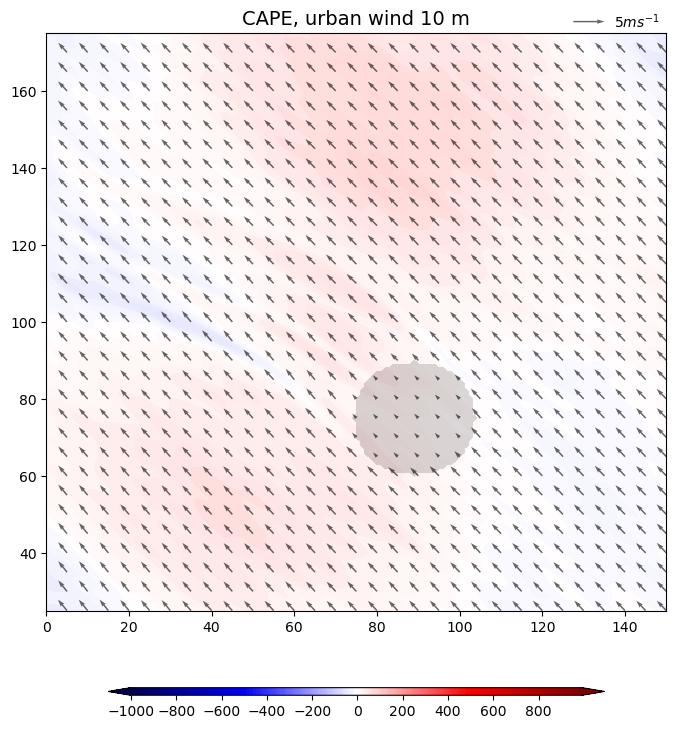

In [39]:
levels=np.arange(-1000,1000,10)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('CAPE, urban wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, to_np(diff[:,:]), levels=levels, cmap='seismic', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')
#for i in range(0,11):
#    ax.plot(xt[i,:],yt[i,:],'k-')
#for i in range(0,11):
    #ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/cape_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [40]:
file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape[i,:,:] = to_np(getvar(ncfile, 'helicity',timeidx=0))[:,:]

cape=np.mean(cape,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

cape2=np.zeros([11,250,250])

ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    cape2[i,:,:] = to_np(getvar(ncfile, 'helicity',timeidx=0))[:,:]

cape2=np.mean(cape2,axis=0)

diff=cape2-cape

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

ua2=np.zeros([11,250,250])
va2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    ua2[i,:,:],va2[i,:,:] = to_np(getvar(ncfile, 'uvmet10',timeidx=0))#[:,:]
    #cape2[i,:,:] = interplevel(wa, p, 950)

ua2=np.mean(ua2,axis=0)
va2=np.mean(va2,axis=0)

In [ ]:
exp=exp1
xt=np.zeros([11,38])
yt=np.zeros([11,38])
for i in range (0,11):
    latlon = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/track_"+str(exp)+"_"+str(i)+".csv")
    #print(latlon['x'].values)
    xt[i,:]=np.array(latlon['x'].values)
    yt[i,:]=latlon['y'].values
    
xm=np.mean(xt,axis=0)
ym=np.mean(yt,axis=0)
xm = xm[~np.isnan(xm)]
ym = ym[~np.isnan(ym)]
print(xm,ym)

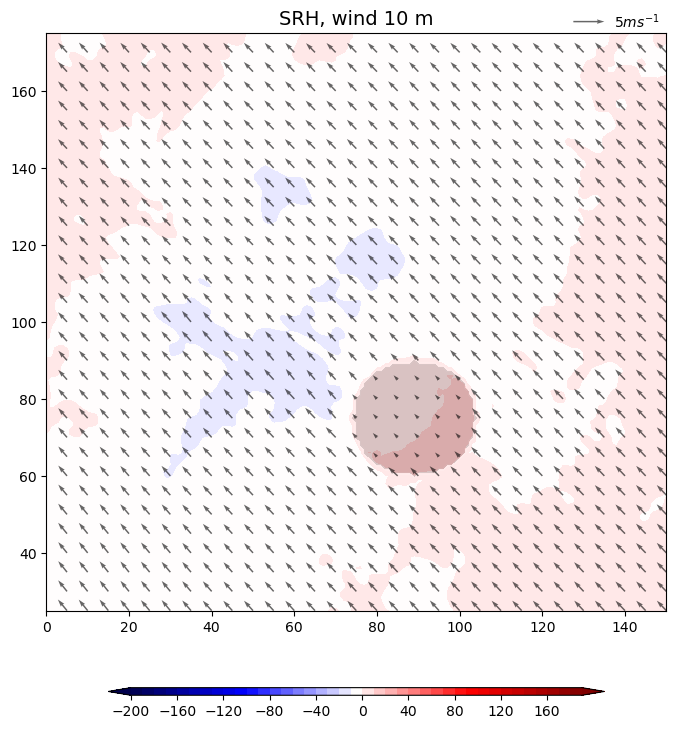

In [41]:
levels=np.arange(-200,200,10)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('SRH, wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, to_np(diff[:,:]), levels=levels, cmap='seismic', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.8, pad=0.1)
#for i in range(0,11):
#    ax.plot(xt[i,:],yt[i,:],'k-')
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')
figname='/glade/u/home/fdemartin/plot/env_diff/srh_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [42]:
file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'wa',timeidx=0))[:,:,:]
    cape[i,:,:] = interplevel(wa, p, 950)[:,:]

cape=np.mean(cape,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

cape2=np.zeros([11,250,250])

ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_15:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'wa',timeidx=0))[:,:,:]
    cape2[i,:,:] = interplevel(wa, p, 950)

cape2=np.mean(cape2,axis=0)

diff=cape2-cape

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

ua2=np.zeros([11,250,250])
va2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    ua2[i,:,:],va2[i,:,:] = to_np(getvar(ncfile, 'uvmet10',timeidx=0))#[:,:]
    #cape2[i,:,:] = interplevel(wa, p, 950)

ua2=np.mean(ua2,axis=0)
va2=np.mean(va2,axis=0)

In [ ]:
exp=exp1
xt=np.zeros([11,38])
yt=np.zeros([11,38])
for i in range (0,11):
    latlon = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/track_"+str(exp)+"_"+str(i)+".csv")
    #print(latlon['x'].values)
    xt[i,:]=np.array(latlon['x'].values)
    yt[i,:]=latlon['y'].values
    
xm=np.mean(xt,axis=0)
ym=np.mean(yt,axis=0)
xm = xm[~np.isnan(xm)]
ym = ym[~np.isnan(ym)]
print(xm,ym)

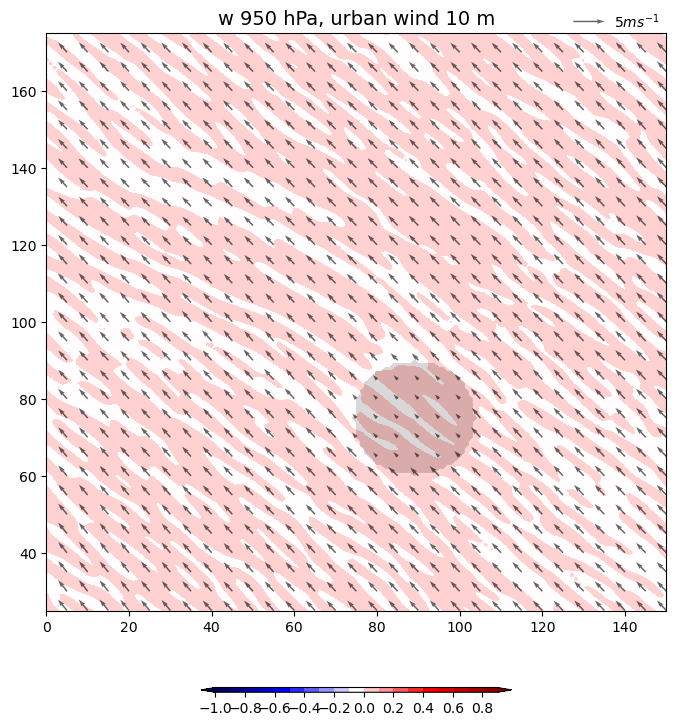

In [43]:
levels=np.arange(-1,1,0.1)
fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('w 950 hPa, urban wind 10 m',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, to_np(diff[:,:]), levels=levels, cmap='seismic', extend='both')
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)
n=5
q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=100,alpha=0.6)
plt.quiverkey(q, X=0.9, Y=1.02,U=5,label='5$ms^{-1}$', labelpos='E')
#for i in range(0,11):
#    ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/w950_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [35]:
#exp0='no_urban'
#exp1='lb_urb12'

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"



cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    cape[i,:,:] = to_np(getvar(ncfile, 'T',timeidx=0))[0,:,:]
    #cape[i,:,:] = interplevel(wa, p, 950)[:,:]

cape=np.mean(cape,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_15:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

cape2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    cape2[i,:,:] = to_np(getvar(ncfile, 'T',timeidx=0))[0,:,:]
    #cape2[i,:,:] = interplevel(wa, p, 950)

cape2=np.mean(cape2,axis=0)

diff=cape2-cape

############# SPECIFIC HUMIDITY

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

q=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    q[i,:,:] = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))[0,:,:]
    #cape[i,:,:] = interplevel(wa, p, 950)[:,:]

q=np.mean(q,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

q2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    q2[i,:,:] = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))[0,:,:]
    #cape2[i,:,:] = interplevel(wa, p, 950)

q2=np.mean(q2,axis=0)

diffq=q2-q

############# WIND

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

ua=np.zeros([11,250,250])
va=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    ua[i,:,:],va[i,:,:] = to_np(getvar(ncfile, 'uvmet10',timeidx=0))#[:,:]
    #va[i,:,:] = to_np(getvar(ncfile, 'ua',timeidx=0))#[:,:]
    #cape[i,:,:] = interplevel(wa, p, 950)[:,:]

ua=np.mean(ua,axis=0)
va=np.mean(va,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

ua2=np.zeros([11,250,250])
va2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    ua2[i,:,:],va2[i,:,:] = to_np(getvar(ncfile, 'uvmet10',timeidx=0))#[:,:]
    #cape2[i,:,:] = interplevel(wa, p, 950)

ua2=np.mean(ua2,axis=0)
va2=np.mean(va2,axis=0)

diffu=ua2-ua
diffv=va2-va

In [ ]:
exp=exp1
xt=np.zeros([11,38])
yt=np.zeros([11,38])
for i in range (0,11):
    latlon = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/track_"+str(exp)+"_"+str(i)+".csv")
    #print(latlon['x'].values)
    xt[i,:]=np.array(latlon['x'].values)
    yt[i,:]=latlon['y'].values
    
xm=np.mean(xt,axis=0)
ym=np.mean(yt,axis=0)
xm = xm[~np.isnan(xm)]
ym = ym[~np.isnan(ym)]
print(xm,ym)

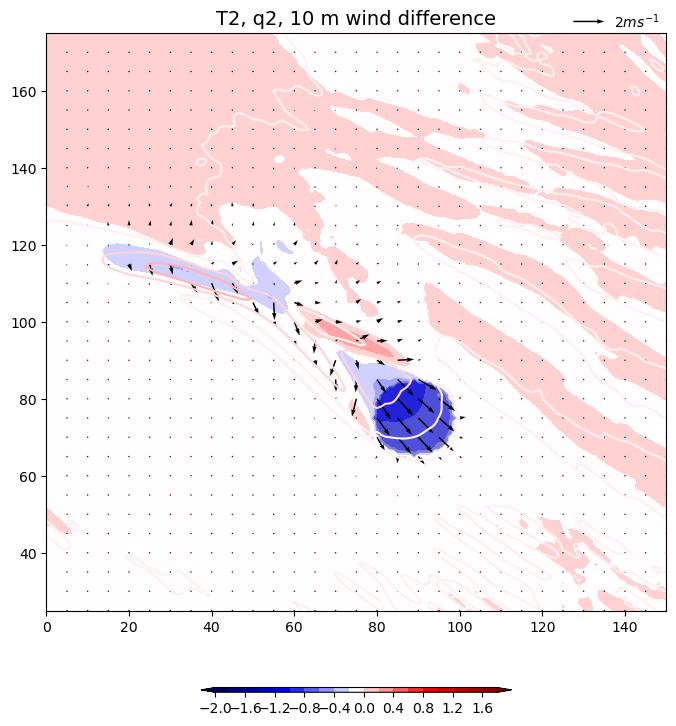

In [36]:
levels=np.arange(-2,2,0.2)
levelsq=np.arange(-0.009,0.009,0.0005)

fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('T2, q2, 10 m wind difference',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, to_np(diff[:,:]), levels=levels, cmap='seismic', extend='both')
#for i in range(0,11):
#    ax.plot(xt[i,:],yt[i,:],'k-')
ax.contour(x, y, to_np(diffq[:,:]), levels=levelsq, cmap='seismic', extend='both',alpha=1)
#ax.contour(x, y, uh, levels=[100,700], colors=['k','k'], extend='both',alpha=1)
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

n=5
q = plt.quiver(x[::n],y[::n],diffu[::n, ::n],diffv[::n, ::n],scale=40)
plt.quiverkey(q, X=0.9, Y=1.02,U=2,label='2$ms^{-1}$', labelpos='E')
#q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=40)
figname='/glade/u/home/fdemartin/plot/env_diff/t2_q2_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [ ]:

pressure=850
file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"
cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'T',timeidx=0))#[:,:]
    cape[i,:,:] = interplevel(wa, p, pressure)[:,:]

cape=np.mean(cape,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

cape2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'T',timeidx=0))#[:,:]
    cape2[i,:,:] = interplevel(wa, p, pressure)

cape2=np.mean(cape2,axis=0)

diff=cape2-cape

############# SPECIFIC HUMIDITY

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

q=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))#[:,:]
    q[i,:,:] = interplevel(wa, p, pressure)[:,:]

q=np.mean(q,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

q2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))#[:,:]
    q2[i,:,:] = interplevel(wa, p, pressure)

q2=np.mean(q2,axis=0)

diffq=q2-q

############# WIND

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

ua=np.zeros([11,250,250])
va=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'ua',timeidx=0))#[:,:]
    wa1 = to_np(getvar(ncfile, 'va',timeidx=0))
    #print(np.shape(p),np.shape(wa))
    #va[i,:,:] = to_np(getvar(ncfile, 'ua',timeidx=0))#[:,:]
    ua[i,:,:] = interplevel(wa, p, pressure)#[:,:]
    va[i,:,:] = interplevel(wa1, p, pressure)

ua=np.mean(ua,axis=0)
va=np.mean(va,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

ua2=np.zeros([11,250,250])
va2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    p=to_np(getvar(ncfile,"pressure",timeidx=0))
    wa = to_np(getvar(ncfile, 'ua',timeidx=0))#[:,:]
    wa1 = to_np(getvar(ncfile, 'va',timeidx=0))
    #va[i,:,:] = to_np(getvar(ncfile, 'ua',timeidx=0))#[:,:]
    ua2[i,:,:] = interplevel(wa, p, pressure)#[:,:]
    va2[i,:,:] = interplevel(wa1, p, pressure)

ua2=np.mean(ua2,axis=0)
va2=np.mean(va2,axis=0)

diffu=ua2-ua
diffv=va2-va

In [ ]:
levels=np.arange(-2,2,0.2)
levelsq=np.arange(-0.009,0.009,0.0005)

fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('T, q, wind at 850 hPa',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max
#c1 = ax.contour(lon, lat, var, levels=mslp_levels, colors="grey", linewidths=1, transform=ccrs.PlateCarree())
#ax.clabel(c1,fmt='%4.1i',fontsize=10)
#cf = ax.contourf(x, y, to_np(var[i,40,:,:]), levels=levels, cmap='viridis', extend='both')
cf = ax.contourf(x, y, to_np(diff[:,:]), levels=levels, cmap='seismic', extend='both')
ax.contour(x, y, to_np(diffq[:,:]), levels=levelsq, cmap='seismic', extend='both',alpha=1)
#ax.contour(x, y, uh, levels=[100,700], colors=['k','k'], extend='both',alpha=1)
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

n=5
q = plt.quiver(x[::n],y[::n],diffu[::n, ::n],diffv[::n, ::n],scale=40)
plt.quiverkey(q, X=0.9, Y=1.02,U=2,label='2$ms^{-1}$', labelpos='E')
#q = plt.quiver(x[::n],y[::n],ua2[::n, ::n],va2[::n, ::n],scale=300)
#for i in range(0,11):
#    ax.plot(xt[i,:],yt[i,:],'k-')
figname='/glade/u/home/fdemartin/plot/env_diff/850v2_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [ ]:
exp1="10km"
xt=np.zeros([11,38])
yt=np.zeros([11,38])
for i in range (0,11):
    latlon = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/track_"+str(exp1)+"_"+str(i)+".csv")
    #print(latlon['x'].values)
    xt[i,:]=np.array(latlon['x'].values)
    yt[i,:]=latlon['y'].values

# xt = xm[~np.isnan(xt,axis=0)]
# yt = ym[~np.isnan(yt,axis=0)]

xm=np.nanmean(xt,axis=0)
ym=np.nanmean(yt,axis=0)
# xm = xm[~np.isnan(xm)]
# ym = ym[~np.isnan(ym)]
print(xm,ym)

exp="no_urban"
xt=np.zeros([11,38])
yt=np.zeros([11,38])
for i in range (0,11):
    latlon = pd.read_csv("/glade/u/home/fdemartin/SPOUT/tracks/track_"+str(exp)+"_"+str(i)+".csv")
    #print(latlon['x'].values)
    xt[i,:]=np.array(latlon['x'].values)
    yt[i,:]=latlon['y'].values
    
xm_nourban=np.nanmean(xt,axis=0)
ym_nourban=np.nanmean(yt,axis=0)
#xm_nourban = xm_nourban[~np.isnan(xm_nourban)]
#ym_nourban = ym_nourban[~np.isnan(ym_nourban)]
print(xm,ym)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"
ncfile = Dataset(file_path+"10/wrfout_d01_2023-05-31_14:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

In [ ]:
levels=np.arange(-2,2,0.2)
levelsq=np.arange(-0.009,0.009,0.0005)
x=np.arange(0,250,1)
y=np.arange(0,250,1)

fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('T, q, wind at 850 hPa',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(25,175)
# MSLP in contours and min max

#ax.contour(x, y, uh, levels=[100,700], colors=['k','k'], extend='both',alpha=1)
gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')

ax.plot(xm_nourban,ym_nourban,'k-')
ax.plot(xm,ym,'r-')
figname='/glade/u/home/fdemartin/plot/env_diff/tracks_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [ ]:
cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

exp0='no_urban_specialcity'
exp1='hb60'

############# SPECIFIC HUMIDITY

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

q=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    q[i,:] = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))[0,:,:]

q=np.mean(q,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

q2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    q2[i,:] = to_np(getvar(ncfile, 'QVAPOR',timeidx=0))[0,:,:]

q2=np.mean(q2,axis=0)

diffq=q2-q

In [ ]:
ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_15:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

levels=np.arange(-2,2,0.2)
levelsq=np.arange(-0.009,0.009,0.0005)

fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('T, q, wind at 850 hPa',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max

cf = ax.contourf(x, y, to_np(diffq[:,:]), levels=levelsq, cmap='seismic', extend='both')

gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

n=5

figname='/glade/u/home/fdemartin/plot/env_diff/850_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()

In [ ]:
cape=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

exp0='30km'
exp1='green'

############# SPECIFIC HUMIDITY

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp0+"/"

q=np.zeros([11,250,250])

x=np.arange(0,250,1)
y=np.arange(0,250,1)

#ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_14:00:00")
#var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    q[i,:] = to_np(getvar(ncfile, 'HFX',timeidx=0))[:,:]

q=np.mean(q,axis=0)

file_path="/glade/derecho/scratch/fdemartin/ens/"+exp1+"/"

q2=np.zeros([11,250,250])

for i in range(0,11):
    ncfile = Dataset(file_path+str(i)+"/wrfout_d01_2023-05-31_14:00:00")
    #latlon=getvar(wrf_files, 'T',timeidx=0)
    #p=to_np(getvar(ncfile,"pressure",timeidx=0))
    q2[i,:] = to_np(getvar(ncfile, 'HFX',timeidx=0))[:,:]

q2=np.mean(q2,axis=0)

diffq=q2-q

In [ ]:
ncfile = Dataset(file_path+"0/wrfout_d01_2023-05-31_15:00:00")
var_lu=to_np(getvar(ncfile,"LU_INDEX",timeidx=0))

levels=np.arange(-2,2,0.2)
levelsq=np.arange(-300,600,10)

fig = plt.figure(figsize=(8, 10))
#print(str(times[i,0])[11:16])
ax = fig.add_subplot(1, 1, 1)
ax.set_title('HFX green roofs',fontsize=14)
ax.set_ylim(25,175)
ax.set_xlim(0,150)
# MSLP in contours and min max

cf = ax.contourf(x, y, to_np(q2[:,:]), levels=levelsq, cmap='seismic', extend='both')

gz = ax.contourf(x, y, to_np(var_lu[:,:]), levels=[30,50,60],colors=['white','black'], alpha=0.15,extend='both')
#gz = ax.contour(x, y, to_np(uh[i,:,:]), levels=[200,900],colors=['black'], extend='both')
cb = fig.colorbar(cf, orientation='horizontal', aspect=65, shrink=0.5, pad=0.1)

n=5

figname='/glade/u/home/fdemartin/plot/env_diff/850_'+exp1
fig.savefig(figname+'.png',bbox_inches='tight')
#plt.close()